# Practice 2 — Florentine Families: Multiplex Networks, Brokerage and Political Power

### Complex Network Features: Marriage and Business Ties, Multiplex Networks, Degree Centrality, Betweenness Centrality, Brokerage, NetworkX, Visualization

**Subject:** Social Networks (SNET)  
**Language:** English  
**Main libraries:** pandas, NetworkX, Matplotlib

## Objectives of the practice

1. Work with a classic historical social-network database: **Padgett's Florentine Families**.
2. Download and read a **two-layer multiplex network** with `pandas`.
3. Distinguish between **marriage alliances** and **business relationships**.
4. Construct separate and combined graphs with **NetworkX**.
5. Compare the topology of different relationship layers.
6. Calculate and interpret node degree, degree centrality, betweenness centrality, adjacency and clustering coefficient.
7. Analyze the **structural position of the Medici family**.
8. Introduce **brokerage**, **multiplexity**, and **political power**.
9. Produce an executive summary and an infographic.

Central question:

> **How can a family become politically powerful not only by having many connections, but by occupying a strategic position between otherwise weakly connected groups?**

##  About the use of AI

The Economist  (18 August 2026),  **Does AI stop children from learning?**

<img src="does-al-stop-children-from-learning-v0-m7gwmp4jkekh1.webp" alt="DoubleGraph" width="600"/>


##  One solution
**Learning How to Learn: How to Succeed in School Without Spending All Your Time Studying; A Guide for Kids and Teens** by Barbara Oakley, PhD, Terrence Sejnowski, PhD, and Alistair McConville (published 2018).

# 1. Description of the problem

Renaissance Florence was organized through overlapping systems of family alliances, economic relationships, and political competition. The same families could be connected through **marriage alliances**, **business relationships**, or both.

This is naturally represented as a **multiplex network**: the same node set participates in several relational layers.

The practical problem is to determine whether the structural position of a family can help explain its capacity to coordinate, broker, or mediate between different parts of the Florentine elite.

## <font color="blue"><b>1.1. Historical background</b></font>

The dataset contains a subset of prominent Florentine families involved in political competition around the early fifteenth century. The classic study is:

**Padgett, J. F. & Ansell, C. K. (1993). _Robust Action and the Rise of the Medici, 1400–1434_. American Journal of Sociology.**

The two relations are:

1. **Marriage alliances**
2. **Business relationships**, including recorded financial ties such as loans, credits and joint partnerships.

The data are conventionally represented as **undirected and unweighted** relations.

A major historical question is why the **Medici** became politically dominant despite the presence of other wealthy and influential families such as the **Strozzi**. Network analysis reformulates the problem structurally: did the Medici connect otherwise separated parts of the elite network?

## <font color="blue"><b>1.1.1 Additional Background background</b></font>

**Ferguson, N. (2017).** *_The Square and the Tower: Networks, Hierarchies and the Struggle for Global Power_*. **Allen Lane (Penguin Books)**.
- Explanation of the difference between vertical hierarchies (i.e. Tower), and flat/network hierarchies (i.e. the city square)

**Easley, D. & Kleinberg, J. (2010).** *_Networks, Crowds, and Markets: Reasoning about a Highly Connected World_*. **Cambridge University Press**.
- Good explanation of the concepts that appear in this practice.

## <font color="blue"><b>1.2. The database</b></font>

We use the openly available **Padgett–Florentine Families multiplex dataset** maintained by CoMuNeLab. The repository documents **16 family nodes**, **2 network layers**, and **35 multiplex connections**. The network is undirected and unweighted.


## <font color="blue"><b>1.3. Complex Network features used in this practice</b></font>

| Feature | Short explanation |
|---|---|
| **Node** | One Florentine family. |
| **Edge** | A recorded relationship between two families. |
| **Layer** | One type of relationship, such as marriage or business. |
| **Multiplex network** | A network in which the same nodes may be connected by several different kinds of edges. |
| **Adjacency** | Two families are adjacent when they share a direct tie in a given layer. |
| **Degree** | Number of direct ties of a node. |
| **Degree centrality** | Degree normalized by the maximum possible number of neighbors. |
| <font color="blue"><b>Betweenness centrality</b></font> | Measures how often a node lies on shortest paths between other nodes; often related to brokerage. |
| <font color="blue"><b>Clustering coefficient</b></font>  | Measures how interconnected a node's neighbors are. |
| **Brokerage** | A structural position connecting actors or groups that otherwise have few direct links. |
| **Visualization** | Graphical representation of families and their relationships. |

####  Comparison <font color="blue"><b>Betweenness centrality</b></font> vs  <font color="blue"><b>Clustering coefficient</b></font>.
<img src="ComparaFamilyBroker.png" alt="DoubleGraph" width="600"/>

## <font color="red"><b>Exercise 1</b></font>

1. What are the **nodes** in this database?
2. What are the two types of **edges**?
3. For clarifying concepts, in two sentences, explain why is this network better represented as a **multiplex network** (mariage and business relationships) than as a single ordinary graph?
4.  For clarifying concepts, , in two sentences, explain from the figure above the pros and cons of the concepts of <font color="blue"><b>Betweenness centrality</b></font> and  <font color="blue"><b>Clustering coefficient</b></font>.

## <font color="green"><b>Exercise 1</b></font>

1. The nodes are the Florentine families included in the dataset.
2. Marriage alliances or buisness relationships.
3. A multiplex network allows us to distinguish between marriage alliances and business relationships while studying the same families. A single ordinary graph may lose this information by combining both types of relationships into one layer.
4. A high clustering coefficient indicates strong local cohesion, which can increase trust and cooperation but may limit connections to other groups (image 1 - high clustering coefficient for all nodes). High betweenness centrality allows a family such as the Medici to act as a broker between groups, gaining strategic importance through its position in the network (image 2).

<img src="DoubleGraph.png" alt="DoubleGraph" width="600"/>

## <font color="red"><b>Exercise 2</b></font>

Suppose two families are connected by both a marriage alliance and a business relationship.

1. Sketch a simple graph of this case.
2. How many edges appear between them in a simple combined graph?
3. What information is lost when layers are collapsed?

## <font color="green"><b>Exercise 2</b></font>

1.

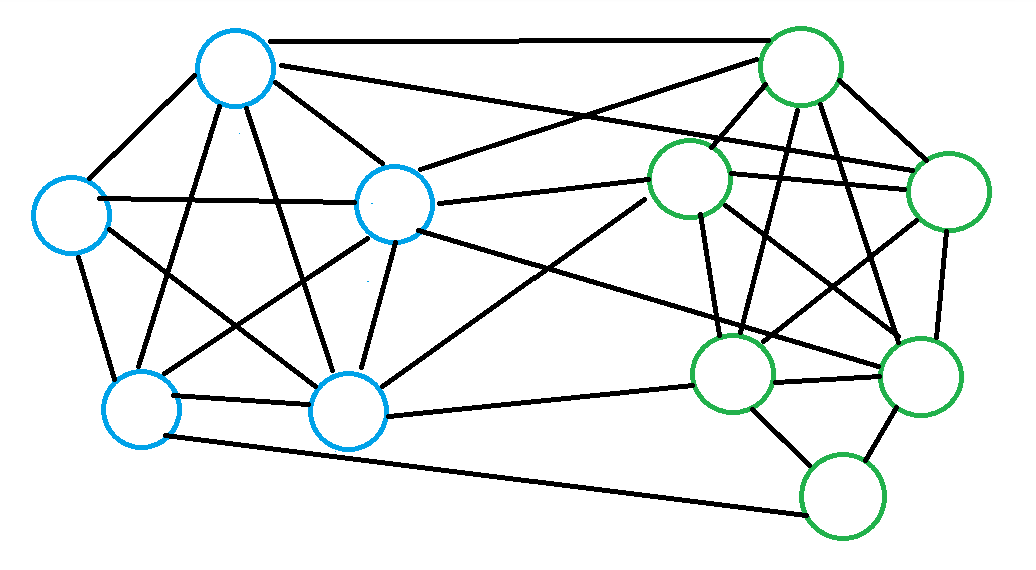

2. There are 8 edges between families, the sames as in a multiplex network. I don't understand the Exercise 2, I think the example is redundant, the importance of multiplex networks is shown better with other exercises.
3. When they are colapsed you don't know if the relations between the two families are of marriage alliances or business relationships, you only know that the families are related

# 3. Practical part

We will download the data, inspect them with `pandas`, map IDs to family names, separate the two layers, and construct NetworkX graphs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pickle

## 3.1. Read the database with pandas

We read from a pickle file the pandas dataframes.

- Note: If you do not know what is a "pickle", it is important that you check what it is and how it is used, which advantatges it has.

In [2]:
with open("florentine_families.pkl", "rb") as f:
    loaded = pickle.load(f)

edges_raw = loaded["edges_raw"]
nodes     = loaded["nodes"]
layers    = loaded["layers"]

print("Loaded successfully from pickle")
print("edges_raw")
print(edges_raw.head(10))
print("Edges table shape:", edges_raw.shape)
print("nodes")
print(nodes.head(10))
print("Nodes table shape:", nodes.shape)
print("layers")
print(layers)
print("Layers table shape:", layers.shape)

Loaded successfully from pickle
edges_raw
   layer_id  source_id  target_id  weight
0         1          1          9       1
1         1          2          6       1
2         1          2          7       1
3         1          2          9       1
4         1          3          5       1
5         1          3          9       1
6         1          4          7       1
7         1          4         11       1
8         1          4         15       1
9         1          5         11       1
Edges table shape: (35, 4)
nodes
   nodeID  nodeLabel
0       1  ACCIAIUOL
1       2    ALBIZZI
2       3  BARBADORI
3       4   BISCHERI
4       5  CASTELLAN
5       6     GINORI
6       7   GUADAGNI
7       8  LAMBERTES
8       9     MEDICI
9      10      PAZZI
Nodes table shape: (16, 2)
layers
   layerID          layerLabel
0        1  marriage_alliances
1        2            business
Layers table shape: (2, 2)


####  Safety check. 

- Always check for mistakes

In [3]:
print("Duplicate edge rows:", edges_raw.duplicated().sum())
self_loops = edges_raw[edges_raw["source_id"] == edges_raw["target_id"]]
print("Self-loops:", len(self_loops))
all_ids = pd.unique(pd.concat([edges_raw["source_id"], edges_raw["target_id"]]))
print("Unique node IDs appearing in edges:", len(all_ids))

Duplicate edge rows: 0
Self-loops: 0
Unique node IDs appearing in edges: 15


## <font color="red"><b>Exercise 3</b></font>

1. How many edge records are present?
2. How many belong to the marriage layer?
3. How many belong to the business layer?
4. Are there self-loops? Why a self-loop should be considered a mistake?
5. Why should these properties be checked before graph construction?

## <font color="green"><b>Exercise 3</b></font>

1. 35 (code below)
2. 20 (code below)
3. 15 (code below)
4. There are not self-loops, is checked in the code before. It can be considered a mistake beacuse is does not show meaningful relationship, so can be a data-quality problem
5. Because they may indicate errors in the original relationship data, and we want to ensure the network accurately represents real relationships.

In [4]:
print("Number of edges: ", len(edges_raw))
marriage_edges = edges_raw[edges_raw["layer_id"] == 1]
print("Number of marriage edges: ", len(marriage_edges))
business_edges = edges_raw[edges_raw["layer_id"] == 2]
print("Number of business edges: ", len(business_edges))

Number of edges:  35
Number of marriage edges:  20
Number of business edges:  15


## 3.3. Replace numeric IDs by family names

In [5]:
node_map = dict(zip(nodes["nodeID"], nodes["nodeLabel"]))
layer_map = dict(zip(layers["layerID"], layers["layerLabel"]))

edges = edges_raw.copy()
edges["source"] = edges["source_id"].map(node_map)
edges["target"] = edges["target_id"].map(node_map)
edges["relation"] = edges["layer_id"].map(layer_map)

edges.head(10)

,layer_id,source_id,target_id,weight,source,target,relation
0,1,1,9,1,ACCIAIUOL,MEDICI,marriage_alliances
1,1,2,6,1,ALBIZZI,GINORI,marriage_alliances
2,1,2,7,1,ALBIZZI,GUADAGNI,marriage_alliances
3,1,2,9,1,ALBIZZI,MEDICI,marriage_alliances
4,1,3,5,1,BARBADORI,CASTELLAN,marriage_alliances
5,1,3,9,1,BARBADORI,MEDICI,marriage_alliances
6,1,4,7,1,BISCHERI,GUADAGNI,marriage_alliances
7,1,4,11,1,BISCHERI,PERUZZI,marriage_alliances
8,1,4,15,1,BISCHERI,STROZZI,marriage_alliances
9,1,5,11,1,CASTELLAN,PERUZZI,marriage_alliances


In [6]:
families = nodes.sort_values("nodeID").copy()
families

,nodeID,nodeLabel
0,1,ACCIAIUOL
1,2,ALBIZZI
2,3,BARBADORI
3,4,BISCHERI
4,5,CASTELLAN
5,6,GINORI
6,7,GUADAGNI
7,8,LAMBERTES
8,9,MEDICI
9,10,PAZZI


## <font color="red"><b>Exercise 4</b></font>

Note: make short answers,  it is just to be aware.

1. Find the node IDs corresponding to **MEDICI** and **STROZZI**.  
- Note: These are the families that were historically opposed. 
2. Why is a mapping table useful even if NetworkX can work with numeric IDs?
3. Which representation is preferable for interpretation: IDs or names?

<font color="red"><b>Python tips</b></font> 

 Understand an practice the following python commands (Matlab lines to Python lines -> 30 to 1)
- dict(zip(nodes["nodeID"], nodes["nodeLabel"]))
- edges["source_id"].map(node_map)
- Why edges = edges_raw.copy()?  Check the meaning of  assignment by reference vs value

## <font color="green"><b>Exercise 4</b></font>

1. MEDICI = 9, STROZZI = 15
2. Becasue it's easier to work with for humans and analyze the results.
3. Names is easier to interpret

# 4. Constructing the three NetworkX graphs

We construct `G_marriage`, `G_business`, and `G_combined`. All 16 families are explicitly added to every graph so isolates, if any, are preserved.

In [7]:
marriage_edges = edges[edges["relation"] == "marriage_alliances"].copy()
business_edges = edges[edges["relation"] == "business"].copy()

all_families = nodes["nodeLabel"].tolist()
G_marriage = nx.Graph(); G_marriage.add_nodes_from(all_families)
G_business = nx.Graph(); G_business.add_nodes_from(all_families)

G_marriage.add_edges_from(marriage_edges[["source", "target"]].itertuples(index=False, name=None))
G_business.add_edges_from(business_edges[["source", "target"]].itertuples(index=False, name=None))
G_combined = nx.compose(G_marriage, G_business)

print("Marriage graph:", G_marriage.number_of_nodes(), "nodes,", G_marriage.number_of_edges(), "edges")
print("Business graph:", G_business.number_of_nodes(), "nodes,", G_business.number_of_edges(), "edges")
print("Combined graph:", G_combined.number_of_nodes(), "nodes,", G_combined.number_of_edges(), "unique edges")

Marriage graph: 16 nodes, 20 edges
Business graph: 16 nodes, 15 edges
Combined graph: 16 nodes, 27 unique edges


## 4.1. Basic network summaries

In [8]:
def graph_summary(G, name):
    N, M = G.number_of_nodes(), G.number_of_edges()
    return {
        "network": name,
        "nodes": N,
        "edges": M,
        "average_degree": 2*M/N if N else np.nan,
        "density": nx.density(G),
        "components": nx.number_connected_components(G),
        "average_clustering": nx.average_clustering(G)
    }

summary = pd.DataFrame([
    graph_summary(G_marriage, "Marriage"),
    graph_summary(G_business, "Business"),
    graph_summary(G_combined, "Combined")
])
summary.round(3)

,network,nodes,edges,average_degree,density,components,average_clustering
0,Marriage,16,20,2.500,0.167,2,0.150
1,Business,16,15,1.875,0.125,6,0.298
2,Combined,16,27,3.375,0.225,2,0.415


## <font color="red"><b>Exercise 5</b></font>

1. Which layer contains more edges?
2. Which layer is denser?
3. Which layer has the larger average degree?
4. Are all families connected in each layer?
5. Why does collapsing the layers generally increase density?

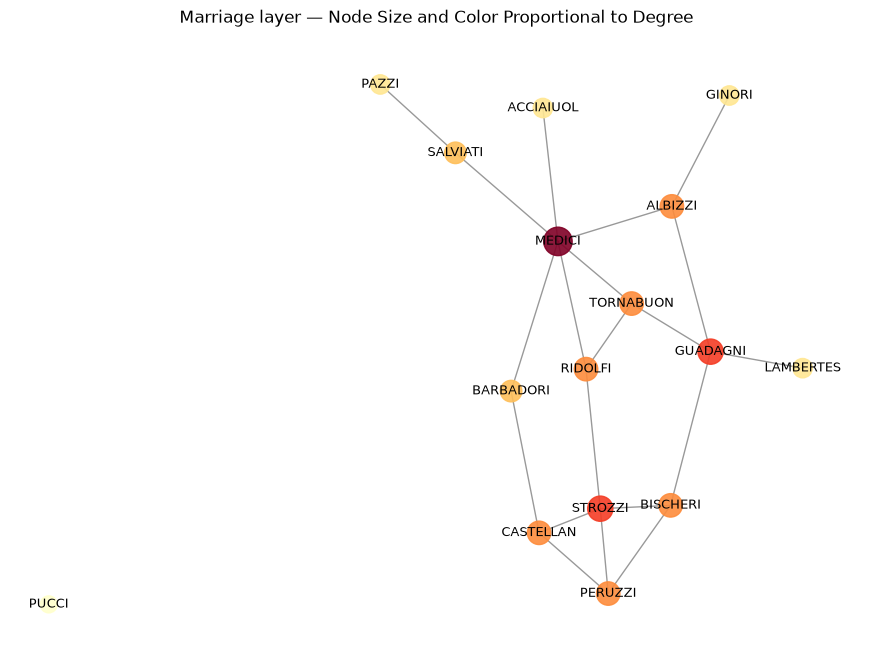

In [14]:
pos = nx.spring_layout(G_marriage, seed=42)

degrees = dict(G_marriage.degree())
node_sizes = [150 + 45 * degrees[node] for node in G_marriage.nodes()]
node_colors = [degrees[node] for node in G_marriage.nodes()]

plt.figure(figsize=(11, 8))

nx.draw_networkx_nodes(
    G_marriage,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.YlOrRd,
    alpha=0.9
)
nx.draw_networkx_edges(G_marriage, pos, alpha=0.4)
nx.draw_networkx_labels(G_marriage, pos, font_size=9)

plt.title("Marriage layer — Node Size and Color Proportional to Degree")
plt.axis("off")
plt.show()

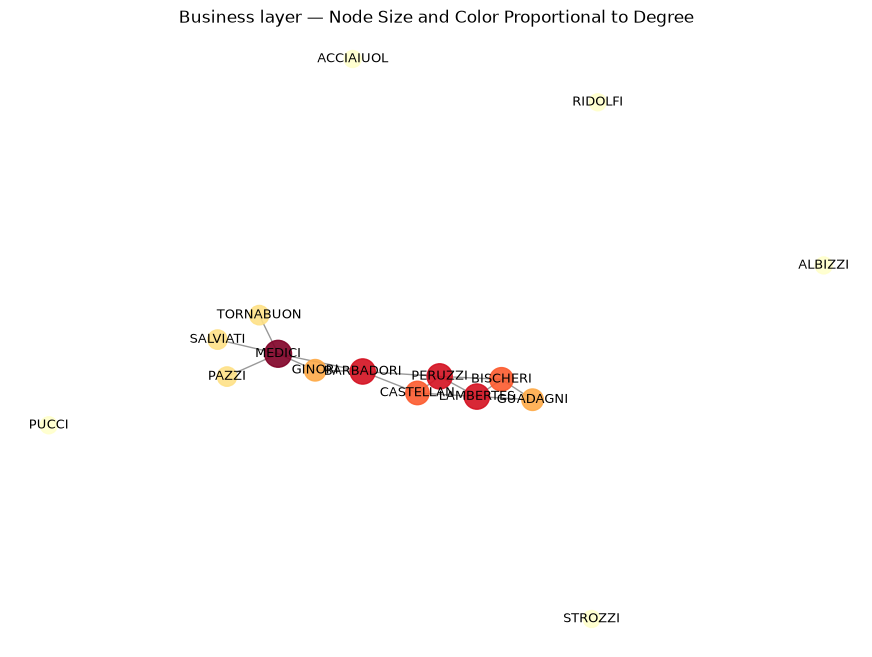

In [15]:
pos = nx.spring_layout(G_business, seed=42)

degrees = dict(G_business.degree())
node_sizes = [150 + 45 * degrees[node] for node in G_business.nodes()]
node_colors = [degrees[node] for node in G_business.nodes()]

plt.figure(figsize=(11, 8))

nx.draw_networkx_nodes(
    G_business,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.YlOrRd,
    alpha=0.9
)
nx.draw_networkx_edges(G_business, pos, alpha=0.4)
nx.draw_networkx_labels(G_business, pos, font_size=9)

plt.title("Business layer — Node Size and Color Proportional to Degree")
plt.axis("off")
plt.show()

## <font color="green"><b>Exercise 5</b></font>

1. The Marriage layer contains more edges.
2. The Marriage layer is more dense, with a 0.167 density.
3. The Marriage layer has larger averagde degree (2.5)
4. Not all families are connected in both layers. In the Marriage layer Pucci is not connected to anyone. In the Business layer, Pucc, Acciaiuol, Ridolfi, Strozzi and Albizzi are not connected to anyone.
5. Because when collapsing layers you add edges in one layer that may not exist in the other layer, so is really probable that you are adding edges that did not exist in the other layer, and this in both ways (in this case in both layers).

# 5. Adjacency and multiplexity

Each layer has its own adjacency matrix. Two families have a **multiplex tie** when they are adjacent in both layers.

In [16]:
A_marriage = nx.to_pandas_adjacency(G_marriage, nodelist=all_families, dtype=int)
A_business = nx.to_pandas_adjacency(G_business, nodelist=all_families, dtype=int)

print("Marriage adjacency matrix:")
display(A_marriage)
print("Business adjacency matrix:")
display(A_business)

Marriage adjacency matrix:


,ACCIAIUOL,ALBIZZI,BARBADORI,BISCHERI,CASTELLAN,GINORI,GUADAGNI,LAMBERTES,MEDICI,PAZZI,PERUZZI,PUCCI,RIDOLFI,SALVIATI,STROZZI,TORNABUON
ACCIAIUOL,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
ALBIZZI,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
BARBADORI,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
BISCHERI,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
CASTELLAN,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0
GINORI,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
GUADAGNI,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,1
LAMBERTES,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
MEDICI,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,1
PAZZI,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


Business adjacency matrix:


,ACCIAIUOL,ALBIZZI,BARBADORI,BISCHERI,CASTELLAN,GINORI,GUADAGNI,LAMBERTES,MEDICI,PAZZI,PERUZZI,PUCCI,RIDOLFI,SALVIATI,STROZZI,TORNABUON
ACCIAIUOL,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
ALBIZZI,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
BARBADORI,0,0,0,0,1,1,0,0,1,0,1,0,0,0,0,0
BISCHERI,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0
CASTELLAN,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0
GINORI,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0
GUADAGNI,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0
LAMBERTES,0,0,0,1,1,0,1,0,0,0,1,0,0,0,0,0
MEDICI,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0,1
PAZZI,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


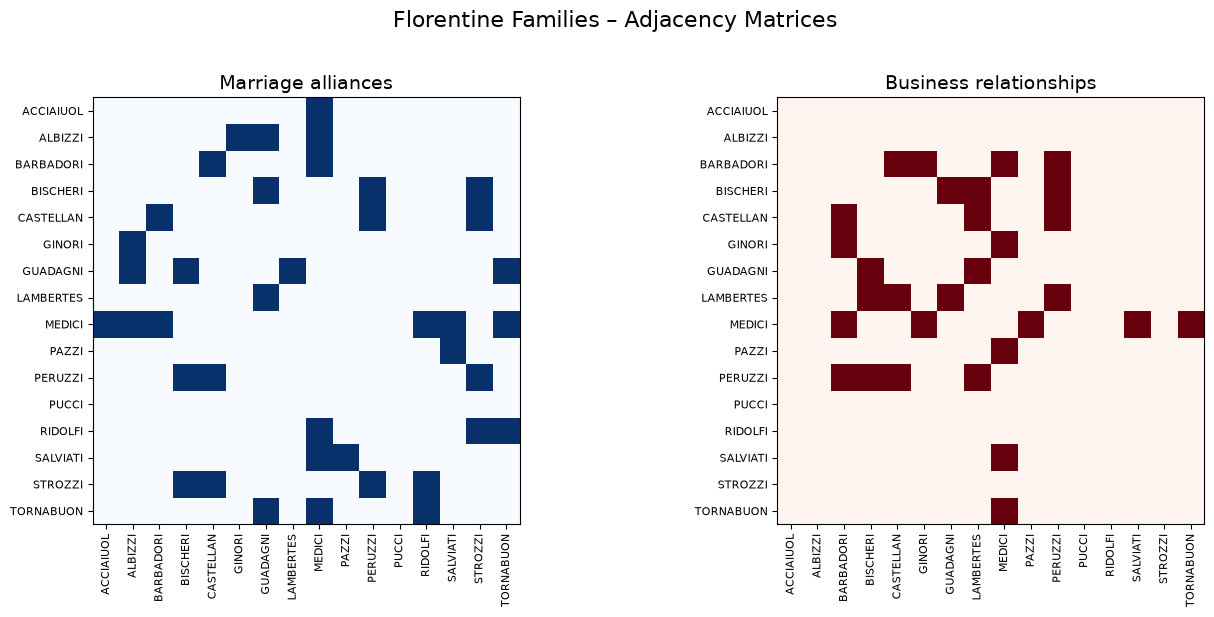

In [17]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------
# Load data (or use the already-loaded variables)
# -------------------------------------------------
BASE_URL = "https://raw.githubusercontent.com/CoMuNeLab/Padgett-Florentine-Families/main/Dataset/"
edges_raw = pd.read_csv(BASE_URL + "Padgett-Florentine-Families_multiplex.edges",
                        sep=r"\s+", header=None,
                        names=["layer_id", "source_id", "target_id", "weight"])
nodes  = pd.read_csv(BASE_URL + "Padgett-Florentine-Families_nodes.txt", sep=r"\s+")
layers = pd.read_csv(BASE_URL + "Padgett-Florentine-Families_layers.txt", sep=r"\s+")

# Map nodeID → family name
id2name = dict(zip(nodes["nodeID"], nodes["nodeLabel"]))
names   = [id2name[i] for i in sorted(id2name)]

# -------------------------------------------------
# Build the two graphs
# -------------------------------------------------
# Marriage (layer 1)
marriage_edges = edges_raw[edges_raw["layer_id"] == 1][["source_id", "target_id"]]
G_mar = nx.from_pandas_edgelist(marriage_edges, "source_id", "target_id")
G_mar = nx.relabel_nodes(G_mar, id2name)

# Business (layer 2)
business_edges = edges_raw[edges_raw["layer_id"] == 2][["source_id", "target_id"]]
G_bus = nx.from_pandas_edgelist(business_edges, "source_id", "target_id")
G_bus = nx.relabel_nodes(G_bus, id2name)

# Ensure all 16 families appear (even isolates)
for n in names:
    G_mar.add_node(n)
    G_bus.add_node(n)

# -------------------------------------------------
# Adjacency matrices (ordered by family name)
# -------------------------------------------------
A_mar = nx.to_pandas_adjacency(G_mar, nodelist=names, dtype=int)
A_bus = nx.to_pandas_adjacency(G_bus, nodelist=names, dtype=int)

# -------------------------------------------------
# Side-by-side heatmaps
# -------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Marriage
im1 = axes[0].imshow(A_mar, cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("Marriage alliances", fontsize=14)
axes[0].set_xticks(range(len(names)))
axes[0].set_yticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=90, fontsize=8)
axes[0].set_yticklabels(names, fontsize=8)

# Business
im2 = axes[1].imshow(A_bus, cmap="Reds", vmin=0, vmax=1)
axes[1].set_title("Business relationships", fontsize=14)
axes[1].set_xticks(range(len(names)))
axes[1].set_yticks(range(len(names)))
axes[1].set_xticklabels(names, rotation=90, fontsize=8)
axes[1].set_yticklabels(names, fontsize=8)

fig.suptitle("Florentine Families – Adjacency Matrices", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 5.1. Number of paths from one node to another: $A^N$
### Why does a power of the adjacency matrix count walks?
The **adjacency matrix** is that its powers provide information about the number of ways of moving between nodes in a network.

Consider an **unweighted graph** with adjacency matrix $A$, where

$A_{ij} = 1$  if nodes $i$ and $j$ are connected, and

$A_{ij} = 0$  otherwise.

The entry $A_{ij}$ tells us whether it is possible to move directly from node $i$ to node $j$ in **one step**.



### From $A$ to $A^2$

The square of the adjacency matrix:

$A^2 = A \cdot A$, then a given element {i,j} has the value  $(A^2)_{ij} = \sum_k A_{ik}A_{kj}$

Each product $A_{ik}A_{kj}$  is equal to 1 only when **both edges exist**:


Then, **$(A^2)_{ij}$ is the number of walks of length 2 from $i$ to $j$.**



### From $A^2$ to $A^3$

For three steps,

$A^3=A\cdot A\cdot A$,  has as  its entries $(A^3)_{ij} = \sum_{k,l} A_{ik}A_{kl}A_{lj}$

A product contributes 1 whenever all three required edges exist:

$i\rightarrow k\rightarrow l\rightarrow j$

Therefore,

**$(A^3)_{ij}$ is the number of walks of length 3 from $i$ to $j$.**



### Generalization to $A^N$

The same argument can be generalized to any positive integer $N$:

**$(A^N)_{ij}$ is the number of walks of length $N$ from node $i$ to node $j$.**

Thus:

| Matrix | Interpretation of entry $(i,j)$ |
|---|---|
| $A$ | Number of walks of length 1 from $i$ to $j$ |
| $A^2$ | Number of walks of length 2 |
| $A^3$ | Number of walks of length 3 |
| $\vdots$ | $\vdots$ |
| $A^N$ | Number of walks of length $N$ |




---

### Important: walks are not necessarily simple paths

Strictly speaking, powers of the adjacency matrix count **walks**, not necessarily **simple paths**.

A **walk** is allowed to visit the same node or edge more than once.

For example,

$A \rightarrow B \rightarrow C \rightarrow B \rightarrow D$

is a valid walk of length 4, even though node $B$ appears twice.

A **simple path**, in contrast, does not repeat nodes.

Therefore, the mathematically precise statement is:

**$(A^N)_{ij}$ gives the number of walks of length exactly $N$ from node $i$ to node $j$.**

It does not, in general, give the number of simple paths.

---

### Application to the Florentine Families network

For the Florentine Families network, calculating

$A^5$

allows us to investigate how many different **five-step walks** connect every pair of families.

A high value of

$(A^5)_{ij}$

means that there are many different sequences of five relationships through which family $i$ can reach family $j$.

This provides information about **indirect connectivity and network structure** that cannot be observed by examining only the immediate relationships represented by $A$.

### 5.1.1 Identify relationships present in both layers

In [18]:
marriage_pairs = {frozenset(e) for e in G_marriage.edges()}
business_pairs = {frozenset(e) for e in G_business.edges()}
both_pairs = marriage_pairs & business_pairs
marriage_only = marriage_pairs - business_pairs
business_only = business_pairs - marriage_pairs

multiplex_summary = pd.DataFrame({
    "tie_type": ["Marriage only", "Business only", "Both layers"],
    "number_of_pairs": [len(marriage_only), len(business_only), len(both_pairs)]
})
multiplex_summary

,tie_type,number_of_pairs
0,Marriage only,12
1,Business only,7
2,Both layers,8


In [19]:
both_edges_df = pd.DataFrame(
    [sorted(tuple(pair)) for pair in both_pairs],
    columns=["family_1", "family_2"]
).sort_values(["family_1", "family_2"]).reset_index(drop=True)
both_edges_df

,family_1,family_2
0,BARBADORI,CASTELLAN
1,BARBADORI,MEDICI
2,BISCHERI,GUADAGNI
3,BISCHERI,PERUZZI
4,CASTELLAN,PERUZZI
5,GUADAGNI,LAMBERTES
6,MEDICI,SALVIATI
7,MEDICI,TORNABUON


### 5.1.2 Paths between nodes.
- Now connected are two families by:
    - Mariage
    - Business

**Meaning:** How many times one gets to a node if one randomly moves on the graph, i.e. how connected they are

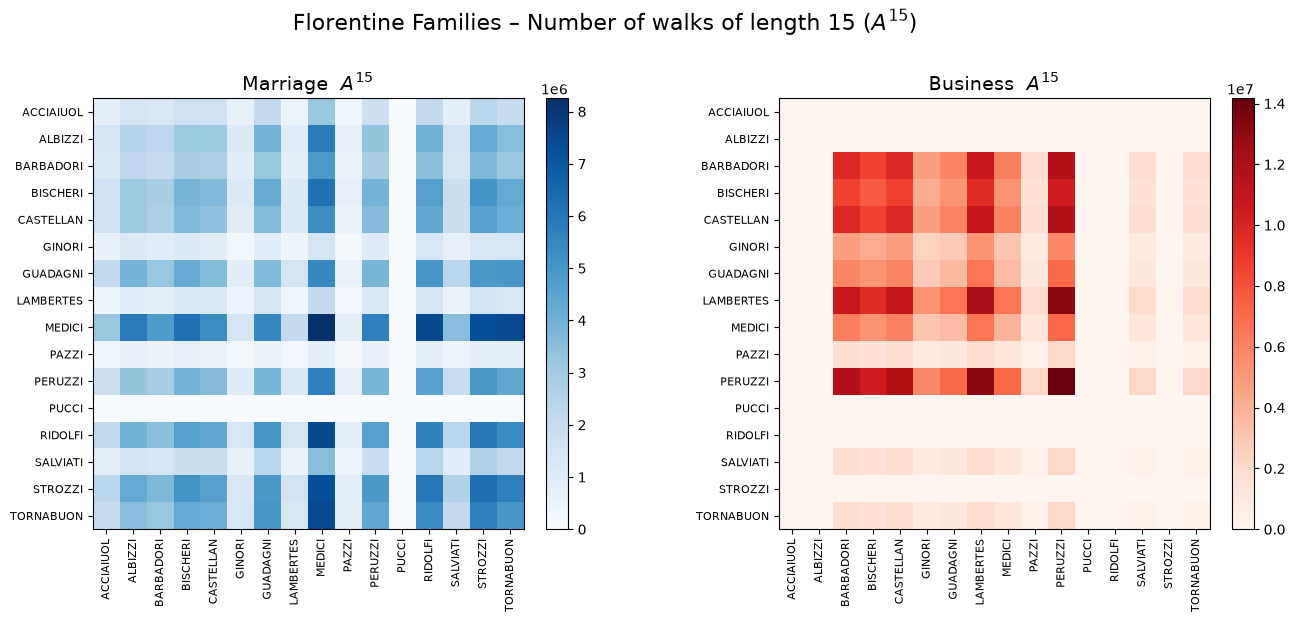

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# A_mar and A_bus are the pandas adjacency matrices from the previous cell
# Convert to numpy for matrix power
A_mar_np = A_mar.values.astype(float)
A_bus_np = A_bus.values.astype(float)

# Compute A^N for each layer
N = 15
A_mar_15 = np.linalg.matrix_power(A_mar_np, N)
A_bus_15 = np.linalg.matrix_power(A_bus_np, N)

# -------------------------------------------------
# Side-by-side plots of A^15
# -------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Marriage A^15
im1 = axes[0].imshow(A_mar_15, cmap="Blues")
axes[0].set_title(r"Marriage  $A^{15}$", fontsize=14)
axes[0].set_xticks(range(len(names)))
axes[0].set_yticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=90, fontsize=8)
axes[0].set_yticklabels(names, fontsize=8)
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Business A^15
im2 = axes[1].imshow(A_bus_15, cmap="Reds")
axes[1].set_title(r"Business  $A^{15}$", fontsize=14)
axes[1].set_xticks(range(len(names)))
axes[1].set_yticks(range(len(names)))
axes[1].set_xticklabels(names, rotation=90, fontsize=8)
axes[1].set_yticklabels(names, fontsize=8)
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

fig.suptitle(r"Florentine Families – Number of walks of length 15 ($A^{15}$)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Order the families according to the total number of walks of length \(N\) in which they appear as the starting node. 
- For each family \(i\), this is the row sum of \(A^N\): $W_i^{(N)} = \sum_j (A^N)_{ij}$

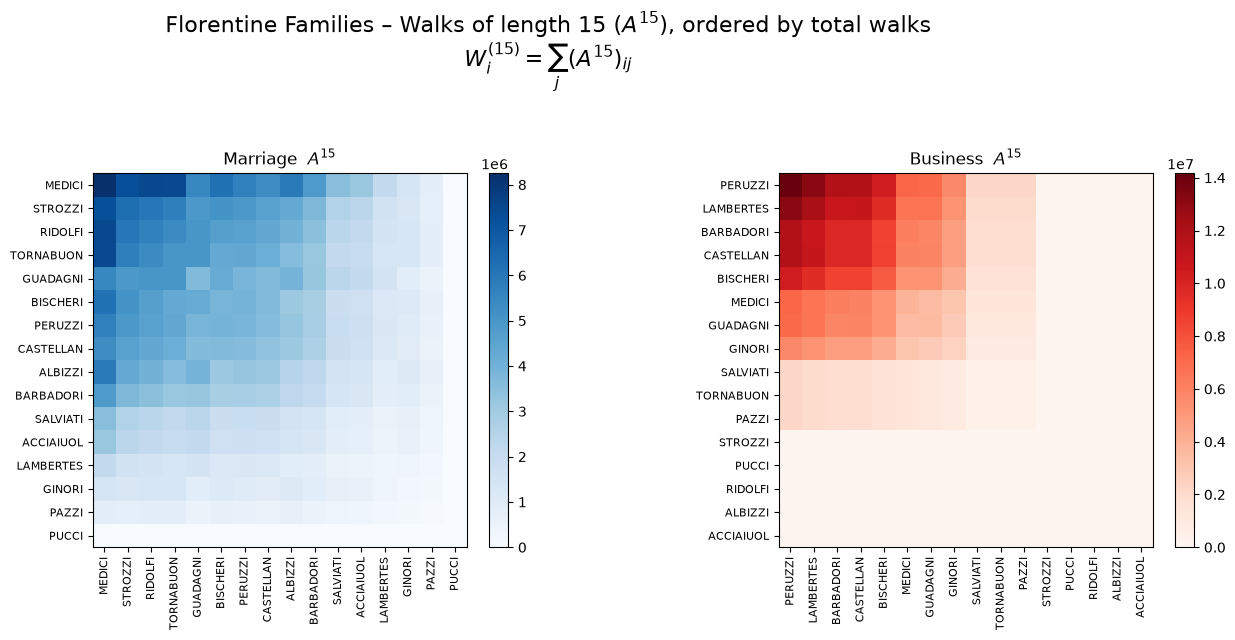

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Convert adjacency matrices to NumPy
A_mar_np = A_mar.values.astype(float)
A_bus_np = A_bus.values.astype(float)

# Compute A^N
N = 15
A_mar_N = np.linalg.matrix_power(A_mar_np, N)
A_bus_N = np.linalg.matrix_power(A_bus_np, N)

# Total number of walks starting from each family
walks_mar = A_mar_N.sum(axis=1)
walks_bus = A_bus_N.sum(axis=1)

# Order families from highest to lowest number of walks
order_mar = np.argsort(walks_mar)[::-1]
order_bus = np.argsort(walks_bus)[::-1]

# Reorder rows and columns
A_mar_ordered = A_mar_N[np.ix_(order_mar, order_mar)]
A_bus_ordered = A_bus_N[np.ix_(order_bus, order_bus)]

names_mar = np.array(names)[order_mar]
names_bus = np.array(names)[order_bus]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(A_mar_ordered, cmap="Blues")
axes[0].set_title(rf"Marriage  $A^{{{N}}}$")
axes[0].set_xticks(range(len(names_mar)))
axes[0].set_yticks(range(len(names_mar)))
axes[0].set_xticklabels(names_mar, rotation=90, fontsize=8)
axes[0].set_yticklabels(names_mar, fontsize=8)
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(A_bus_ordered, cmap="Reds")
axes[1].set_title(rf"Business  $A^{{{N}}}$")
axes[1].set_xticks(range(len(names_bus)))
axes[1].set_yticks(range(len(names_bus)))
axes[1].set_xticklabels(names_bus, rotation=90, fontsize=8)
axes[1].set_yticklabels(names_bus, fontsize=8)
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

fig.suptitle(
    rf"Florentine Families – Walks of length {N} ($A^{{{N}}}$), ordered by total walks"
    "\n"
    rf"$W_i^{{({N})}} = \sum_j (A^{{{N}}})_{{ij}}$",
    fontsize=16, y=1.05
)

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 6</b></font>

1. How many pairs are connected only by marriage in the Adjencency Matrix?. Which are the most connected by number of paths?
2. How many only by business?. Which are the most connected by number of paths?
3. How many are connected in both layers in the adjacency matrices? Is it inherited in the number of paths matrix?


In [29]:
print("Marriage: ", len(marriage_only))
print("Business: ", len(business_only))

Marriage:  12
Business:  7


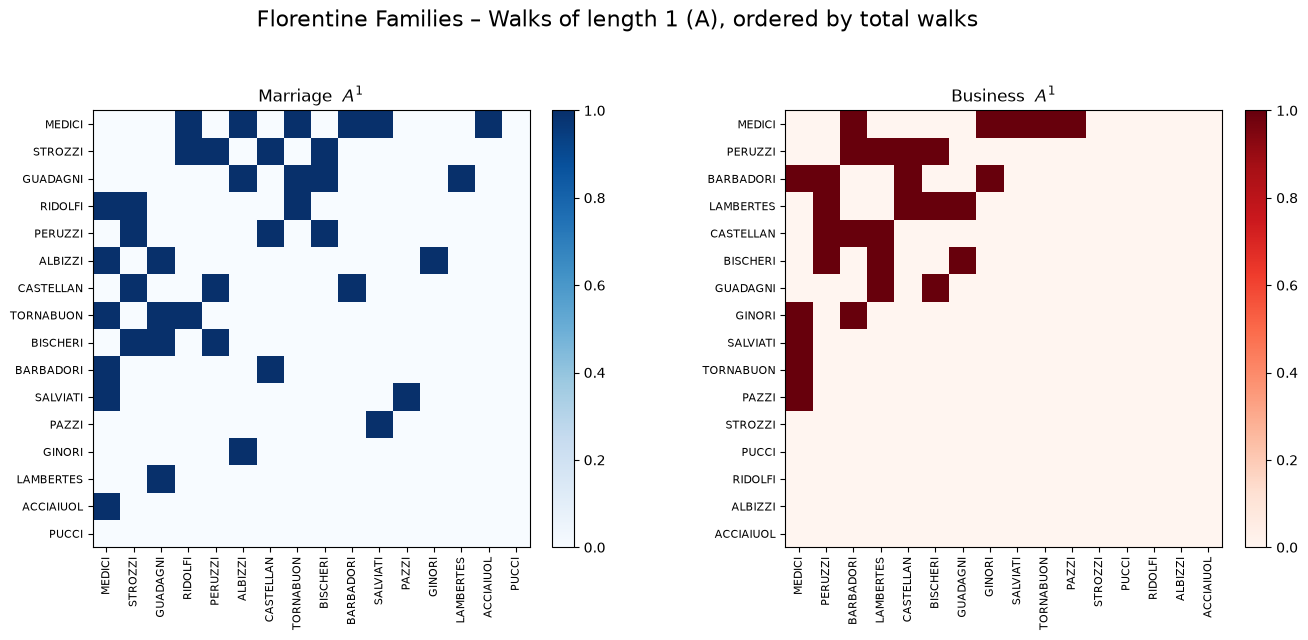

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Convert adjacency matrices to NumPy
# A_mar = A_mar.values.astype(float)
# A_bus = A_bus.values.astype(float)

# Total number of walks starting from each family
walks_mar = A_mar.sum(axis=1)
walks_bus = A_bus.sum(axis=1)

# Order families from highest to lowest number of walks
order_mar = np.argsort(walks_mar)[::-1]
order_bus = np.argsort(walks_bus)[::-1]

# Reorder rows and columns
A_mar_ordered = A_mar[np.ix_(order_mar, order_mar)]
A_bus_ordered = A_bus[np.ix_(order_bus, order_bus)]

names_mar = np.array(names)[order_mar]
names_bus = np.array(names)[order_bus]

# Plot
N = 1
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(A_mar_ordered, cmap="Blues")
axes[0].set_title(rf"Marriage  $A^{{{N}}}$")
axes[0].set_xticks(range(len(names_mar)))
axes[0].set_yticks(range(len(names_mar)))
axes[0].set_xticklabels(names_mar, rotation=90, fontsize=8)
axes[0].set_yticklabels(names_mar, fontsize=8)
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(A_bus_ordered, cmap="Reds")
axes[1].set_title(rf"Business  $A^{{{N}}}$")
axes[1].set_xticks(range(len(names_bus)))
axes[1].set_yticks(range(len(names_bus)))
axes[1].set_xticklabels(names_bus, rotation=90, fontsize=8)
axes[1].set_yticklabels(names_bus, fontsize=8)
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

fig.suptitle(
"Florentine Families – Walks of length 1 (A), ordered by total walks"
    ,fontsize=16, y=1.05
)

plt.tight_layout()
plt.show()

## <font color="green"><b>Exercise 6</b></font>

1. There are 12 pairs only connected in the Marriage layer. The once with most paths are the Medici with 6, the Strozzi and the Guadagni and with 4 and then the Ridolfi, the Peruzzi, the Albizzi, the Castellan, the Tornaboun and the Bizceri with 3. This taking the Adjacency Matrix of length 1.
2. There are 7 pairs only connected in the Business layer. The once with most paths are the Medici with 6, the Peruzzi, Barbadori and Lamberts with 4, followed by the Castellan ans Bischeri with 3. This taking the Adjacency Matrix of length 1.
3. There are 8 pairs connected in both layers. Yes it is inherited, because the families that are connected in both layers are all in between the most connected nodes when working with the adjacency matrix of length 15, in exeption of the Strozzi, that is not in both layers but is in the second place of the marriadeg adgacency matrix of length 15. 


# 6. Network visualization

Use the same node positions for every layer so that differences in the figures reflect network structure rather than a different layout.

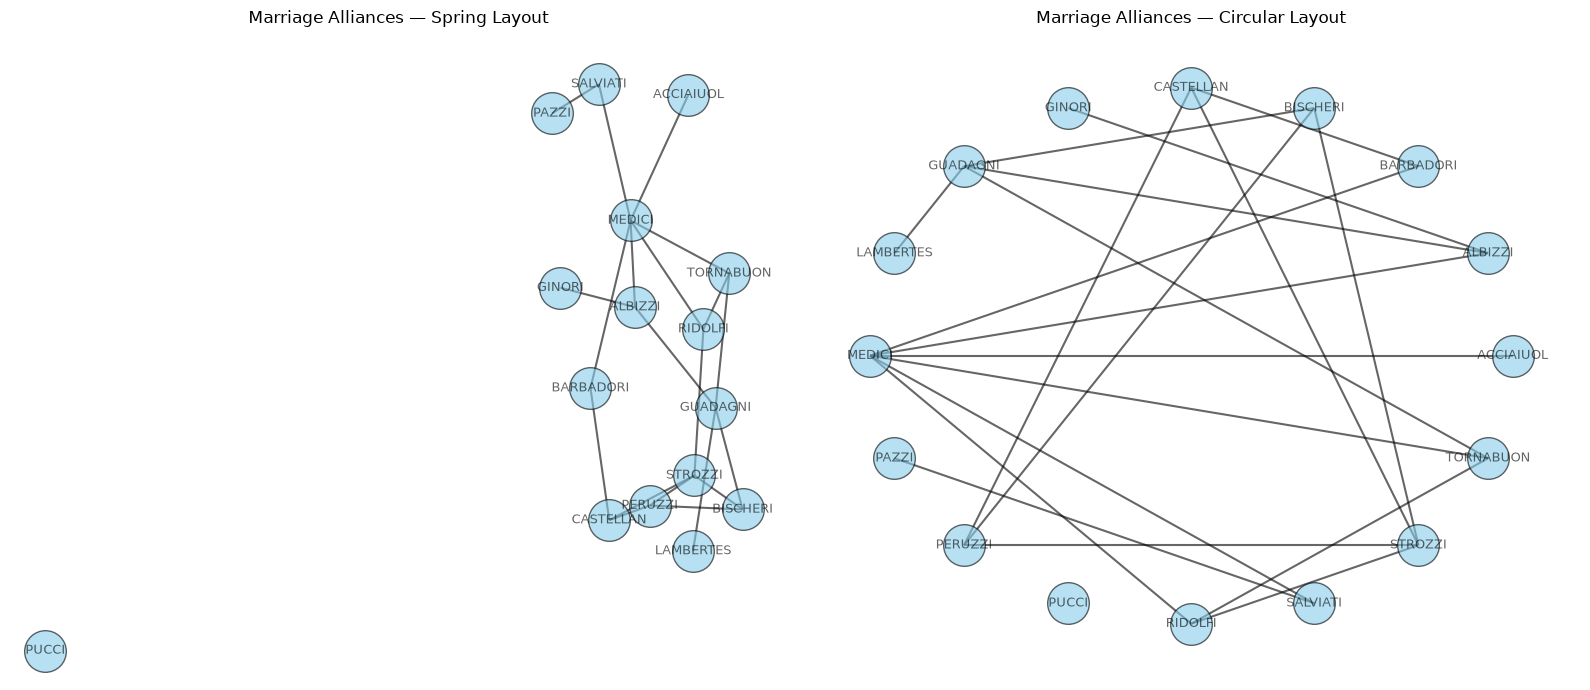

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: Spring layout
pos_spring = nx.spring_layout(G_combined, seed=42)
nx.draw_networkx(G_marriage, pos=pos_spring, ax=axes[0], with_labels=True, node_size=900, font_size=9, width=1.5, node_color="skyblue", alpha=0.6, edgecolors="black")
axes[0].set_title("Marriage Alliances — Spring Layout")
axes[0].axis("off")

# Right: Circular layout
pos_circle = nx.circular_layout(G_combined)
nx.draw_networkx(G_marriage, pos=pos_circle, ax=axes[1], with_labels=True, node_size=900, font_size=9, width=1.5, node_color="skyblue", alpha=0.6, edgecolors="black")
axes[1].set_title("Marriage Alliances — Circular Layout")
axes[1].axis("off")

plt.tight_layout()
plt.show()

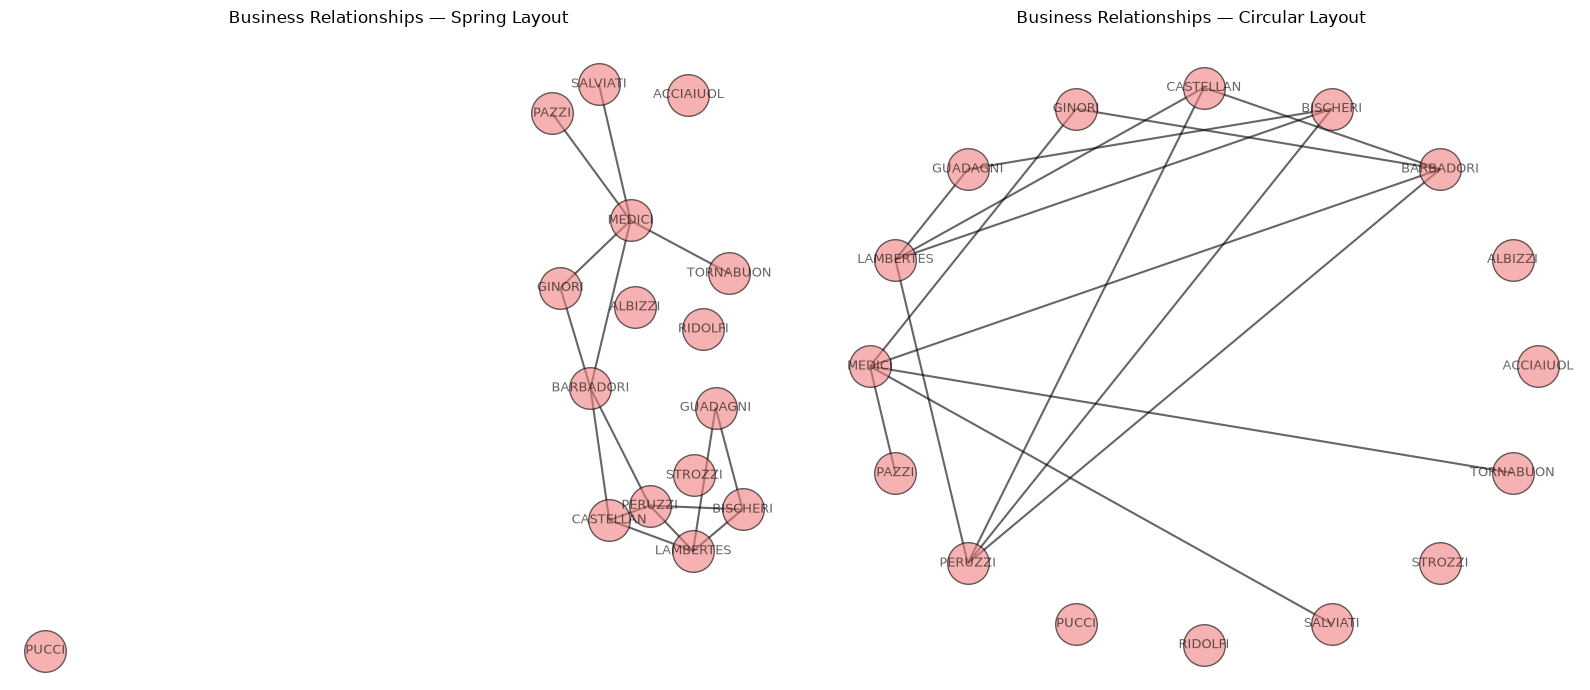

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: Spring layout
pos_spring = nx.spring_layout(G_combined, seed=42)
nx.draw_networkx(G_business, pos=pos_spring, ax=axes[0], with_labels=True, node_size=900, font_size=9, width=1.5, node_color="lightcoral", alpha=0.6, edgecolors="black")
axes[0].set_title("Business Relationships — Spring Layout")
axes[0].axis("off")

# Right: Circular layout
pos_circle = nx.circular_layout(G_combined)
nx.draw_networkx(G_business, pos=pos_circle, ax=axes[1], with_labels=True, node_size=900, font_size=9, width=1.5, node_color="lightcoral", alpha=0.6, edgecolors="black")
axes[1].set_title("Business Relationships — Circular Layout")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 6.1. Multiplex visualization

Solid edges represent marriage; dashed edges represent business.

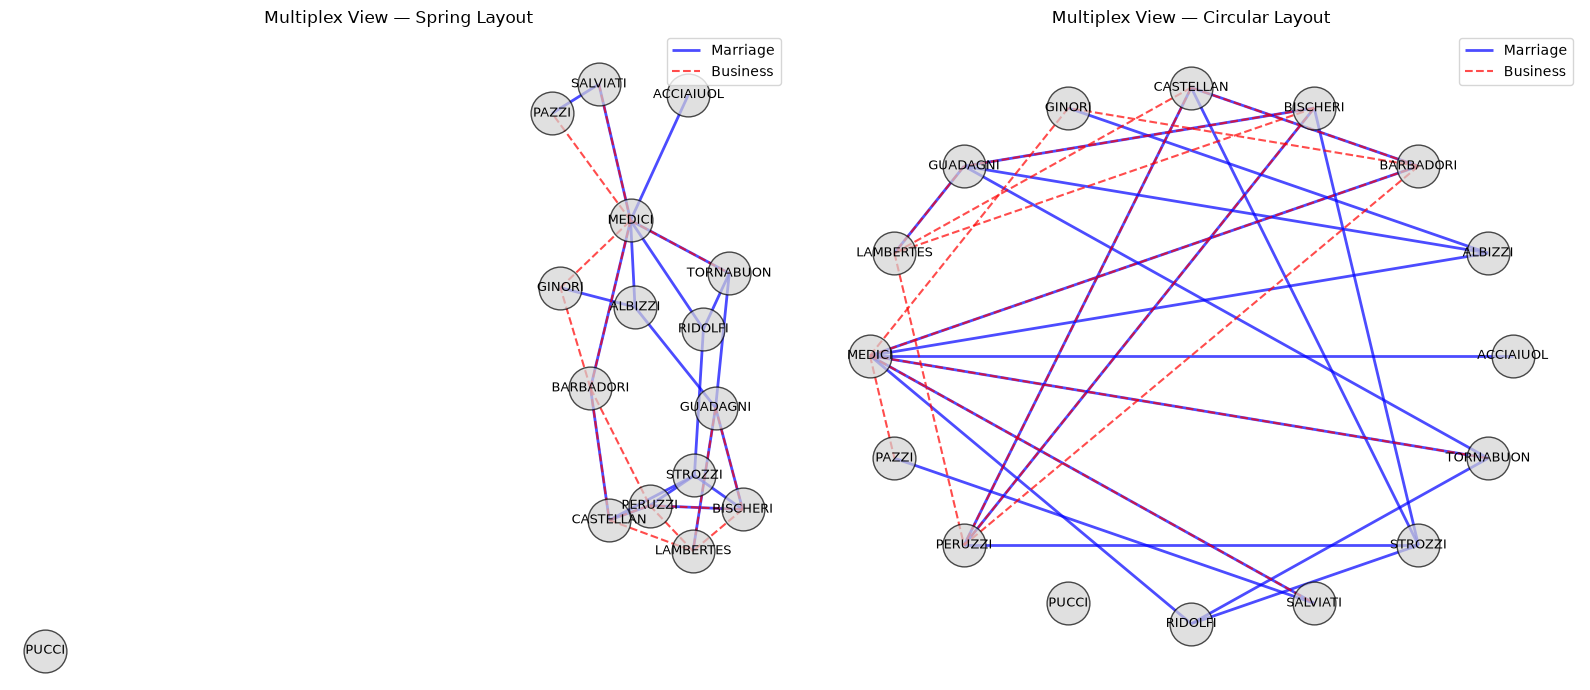

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# -------------------------------------------------
# Left: Spring layout
# -------------------------------------------------
pos_spring = nx.spring_layout(G_combined, seed=42)

nx.draw_networkx_nodes(G_combined, pos_spring, ax=axes[0], node_size=950, node_color="lightgray", alpha=0.7, edgecolors="black")
nx.draw_networkx_labels(G_combined, pos_spring, ax=axes[0], font_size=9)
nx.draw_networkx_edges(G_marriage, pos_spring, ax=axes[0], width=2.0, alpha=0.7, edge_color="blue", label="Marriage")
nx.draw_networkx_edges(G_business, pos_spring, ax=axes[0], width=1.5, alpha=0.7, style="dashed", edge_color="red", label="Business")
axes[0].set_title("Multiplex View — Spring Layout")
axes[0].axis("off")
axes[0].legend()

# -------------------------------------------------
# Right: Circular layout
# -------------------------------------------------
pos_circle = nx.circular_layout(G_combined)

nx.draw_networkx_nodes(G_combined, pos_circle, ax=axes[1], node_size=950, node_color="lightgray", alpha=0.7, edgecolors="black")
nx.draw_networkx_labels(G_combined, pos_circle, ax=axes[1], font_size=9)
nx.draw_networkx_edges(G_marriage, pos_circle, ax=axes[1], width=2.0, alpha=0.7, edge_color="blue", label="Marriage")
nx.draw_networkx_edges(G_business, pos_circle, ax=axes[1], width=1.5, alpha=0.7, style="dashed", edge_color="red", label="Business")
axes[1].set_title("Multiplex View — Circular Layout")
axes[1].axis("off")
axes[1].legend()

plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 7</b></font>

1. Which families appear visually central in the marriage network?
2. Which appear central in the business network?
3. Does MEDICI occupy the same structural position in both layers?
4. Identify a family that is more prominent in one layer than the other.
5. Why is a common layout useful for comparison? Are there shorter paths when both networks are joined together?

## <font color="green"><b>Exercise 7</b></font>

1. The families: Medici, Albizzi, Ridolfi and Guadagni.
2. The families: Medici, Barbadori and Ginori.
3. Yes, the Medici family ocuccups a similar central position in both layers.
4. The Ridolfi family is central and important node of connections in the marriage layer but has no edges in the business layer.
5. Common layout is useful for comparison beacuse it keeps the position of the families the same for both networks, and this makes easier to identify similarities and differences between marriage and business. Yes both networks are joined there are shorter paths, beacuse appears edges that colud not appear before, a connection that was 3 steps in marriage layer, with the addition of the business layer maight turn to 1 step.

# 7. Degree and degree centrality

For an undirected graph, degree centrality is

$
C_D(i)=\frac{k_i}{N-1}.
$

Degree is a **local** measure because it considers direct connections only.

In [43]:
dcm = nx.degree_centrality(G_marriage)
dcb = nx.degree_centrality(G_business)
dcc = nx.degree_centrality(G_combined)

degree_table = pd.DataFrame({
    "family": all_families,
    "degree_marriage": [G_marriage.degree(f) for f in all_families],
    "degree_business": [G_business.degree(f) for f in all_families],
    "degree_combined": [G_combined.degree(f) for f in all_families],
    "degree_centrality_marriage": [dcm[f] for f in all_families],
    "degree_centrality_business": [dcb[f] for f in all_families],
    "degree_centrality_combined": [dcc[f] for f in all_families]
})
degree_table.sort_values("degree_combined", ascending=False).reset_index(drop=True).round(3)

,family,degree_marriage,degree_business,degree_combined,degree_centrality_marriage,degree_centrality_business,degree_centrality_combined
0,MEDICI,6,5,8,0.400,0.333,0.533
1,PERUZZI,3,4,5,0.200,0.267,0.333
2,BISCHERI,3,3,4,0.200,0.200,0.267
3,BARBADORI,2,4,4,0.133,0.267,0.267
4,LAMBERTES,1,4,4,0.067,0.267,0.267
5,STROZZI,4,0,4,0.267,0.000,0.267
6,GUADAGNI,4,2,4,0.267,0.133,0.267
7,CASTELLAN,3,3,4,0.200,0.200,0.267
8,TORNABUON,3,1,3,0.200,0.067,0.200
9,GINORI,1,2,3,0.067,0.133,0.200


<font color="red"><b>Python tips</b></font> 
Understand the 'sort_values' command, i.e. degree_table.sort_values("degree_combined", ascending=False)

## 7.1. Marriage degree versus business degree

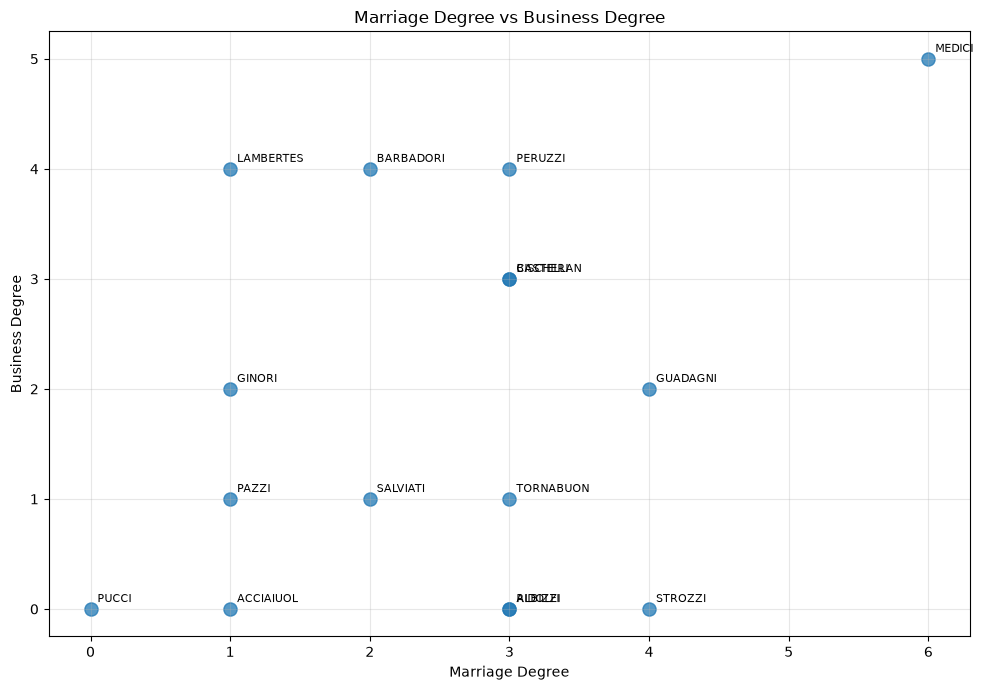

In [44]:
plt.figure(figsize=(10,7))
plt.scatter(degree_table["degree_marriage"], degree_table["degree_business"], s=90, alpha=0.75)
for _, row in degree_table.iterrows():
    plt.annotate(row["family"], (row["degree_marriage"], row["degree_business"]),
                 xytext=(5,5), textcoords="offset points", fontsize=8)
plt.xlabel("Marriage Degree"); plt.ylabel("Business Degree")
plt.title("Marriage Degree vs Business Degree")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## <font color="red"><b>Exercise 8</b></font>

1. Which family has the highest marriage degree?
2. Which has the highest business degree?
3. Which families are highly connected in both layers?
4. Does the family with the highest total degree necessarily have the greatest brokerage potential?
5. Why may degree alone be insufficient for analyzing political power?
6. Comment briefly on the scatter plot Marriage Degree vs Business Degree. Note that powerfull families like Strozzi and Lambertes have power due to different origins.

## <font color="green"><b>Exercise 8</b></font>

1. The Medici family has the highest marriage degree, with 6.
2. The Medici family has the highest business degree, with 5.
3. Medici is the family with most connections it both layers, with 8 connections, and the second one is Peruzzi with 5 combined connections.
4. Not necessary, but in this case is true, the Medici family is the most connected and also is the one with highest brokerage. But can be a case with 9 nodes, 4 conneted to each other and 4 conneted to each other and then 1 only node connecting bot groups, in this case this node is the less dense but has the hoghest brokerage.
5. Becasue in polithics is importante to have contacas, but it is also really imporant to be a brokerage node, to have links between different groups.
6. In the scatter plot we can se why Medici family was the most influenctial, and also we can note why Strozzi that has a lof of marriages and Lambertes that hat a high busines power were not the most influential families, and this is beacuse they had a grate power (connections) in one layer but insufficient in the other layer.

# 8. Betweenness centrality and brokerage

**Betweenness centrality** measures how often a node lies on shortest paths between other nodes:

$
C_B(v)=\sum_{s
eq v
eq t}\frac{\sigma_{st}(v)}{\sigma_{st}}.
$

A node with high betweenness can occupy a **brokerage position** between groups. A broker may connect otherwise separated actors, mediate access, coordinate information, bridge factions, or gain strategic autonomy by avoiding complete dependence on one dense cluster.

In [45]:
bet_marriage = nx.betweenness_centrality(G_marriage, normalized=True)
bet_business = nx.betweenness_centrality(G_business, normalized=True)
bet_combined = nx.betweenness_centrality(G_combined, normalized=True)

centrality_table = degree_table.copy()
centrality_table["betweenness_marriage"] = centrality_table["family"].map(bet_marriage)
centrality_table["betweenness_business"] = centrality_table["family"].map(bet_business)
centrality_table["betweenness_combined"] = centrality_table["family"].map(bet_combined)
centrality_table.sort_values("betweenness_combined", ascending=False).reset_index(drop=True).round(3)

,family,degree_marriage,degree_business,degree_combined,degree_centrality_marriage,degree_centrality_business,degree_centrality_combined,betweenness_marriage,betweenness_business,betweenness_combined
0,MEDICI,6,5,8,0.400,0.333,0.533,0.452,0.229,0.413
1,BARBADORI,2,4,4,0.133,0.267,0.267,0.081,0.238,0.158
2,GUADAGNI,4,2,4,0.267,0.133,0.267,0.221,0.000,0.112
3,RIDOLFI,3,0,3,0.200,0.000,0.200,0.098,0.000,0.071
4,PERUZZI,3,4,5,0.200,0.267,0.333,0.019,0.129,0.061
5,ALBIZZI,3,0,3,0.200,0.000,0.200,0.184,0.000,0.059
6,STROZZI,4,0,4,0.267,0.000,0.267,0.089,0.000,0.054
7,TORNABUON,3,1,3,0.200,0.067,0.200,0.079,0.000,0.052
8,CASTELLAN,3,3,4,0.200,0.200,0.267,0.048,0.048,0.033
9,LAMBERTES,1,4,4,0.067,0.267,0.267,0.000,0.057,0.032


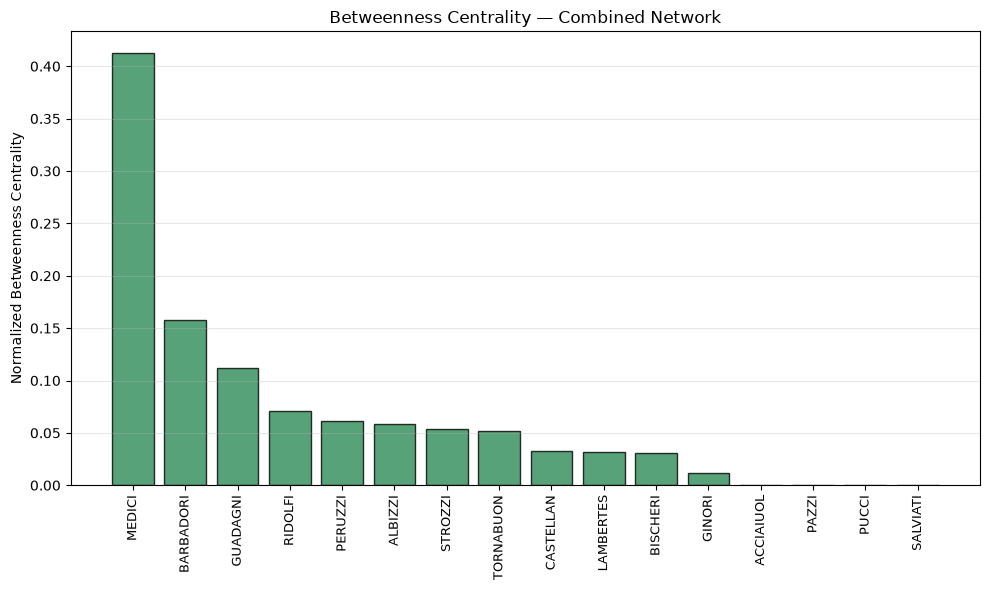

In [46]:

# Sort by combined betweenness
df_plot = centrality_table.sort_values("betweenness_combined", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
plt.bar(df_plot["family"], df_plot["betweenness_combined"], color="seagreen", edgecolor="black", alpha=0.8)

plt.ylabel("Normalized Betweenness Centrality")
plt.title("Betweenness Centrality — Combined Network")
plt.xticks(rotation=90, fontsize=9)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8.1. Degree versus betweenness

This scatter plot separates **many direct ties** from **strategic position between others**.

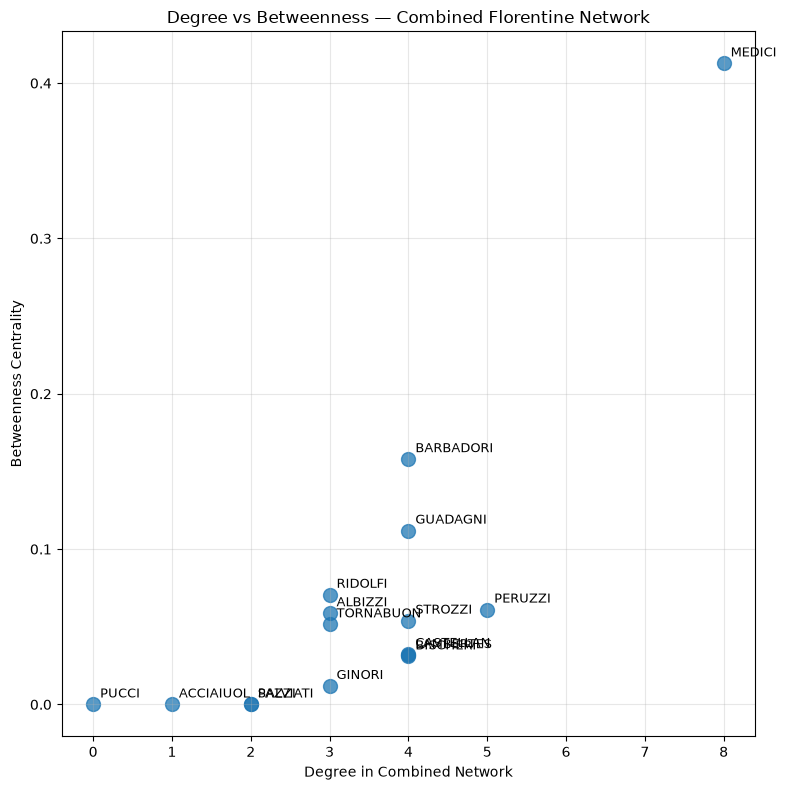

In [47]:
plt.figure(figsize=(8,8))
plt.scatter(centrality_table["degree_combined"], centrality_table["betweenness_combined"], s=100, alpha=0.75)
for _, row in centrality_table.iterrows():
    plt.annotate(row["family"], (row["degree_combined"], row["betweenness_combined"]),
                 xytext=(5,5), textcoords="offset points", fontsize=9)
plt.xlabel("Degree in Combined Network"); plt.ylabel("Betweenness Centrality")
plt.title("Degree vs Betweenness — Combined Florentine Network")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## <font color="red"><b>Exercise 9</b></font>

1. Which family has the highest betweenness in the combined network? Make a short reflection based on the paths observed in $A^{5}$.
2. Compare MEDICI and STROZZI.
3. Does the family with highest betweenness also have the highest degree?
4. Explain the difference between **connectivity** and **brokerage**.
- Note: 
**Connectivity** refers to how many direct relationships an actor has in the network. In Network Science, this is closely related to **degree**. A highly connected family has many direct links to other families.

**Brokerage** refers to occupying a strategic position between actors or groups that are not strongly connected to each other. A broker may therefore have fewer total links than another actor, but its links connect otherwise separated parts of the network.


$$
\text{Connectivity} \approx \text{How many actors do I know?}
$$

$$
\text{Brokerage} \approx \text{Which otherwise separated actors or groups do I connect?}
$$


5. Why might brokerage provide a political advantage?

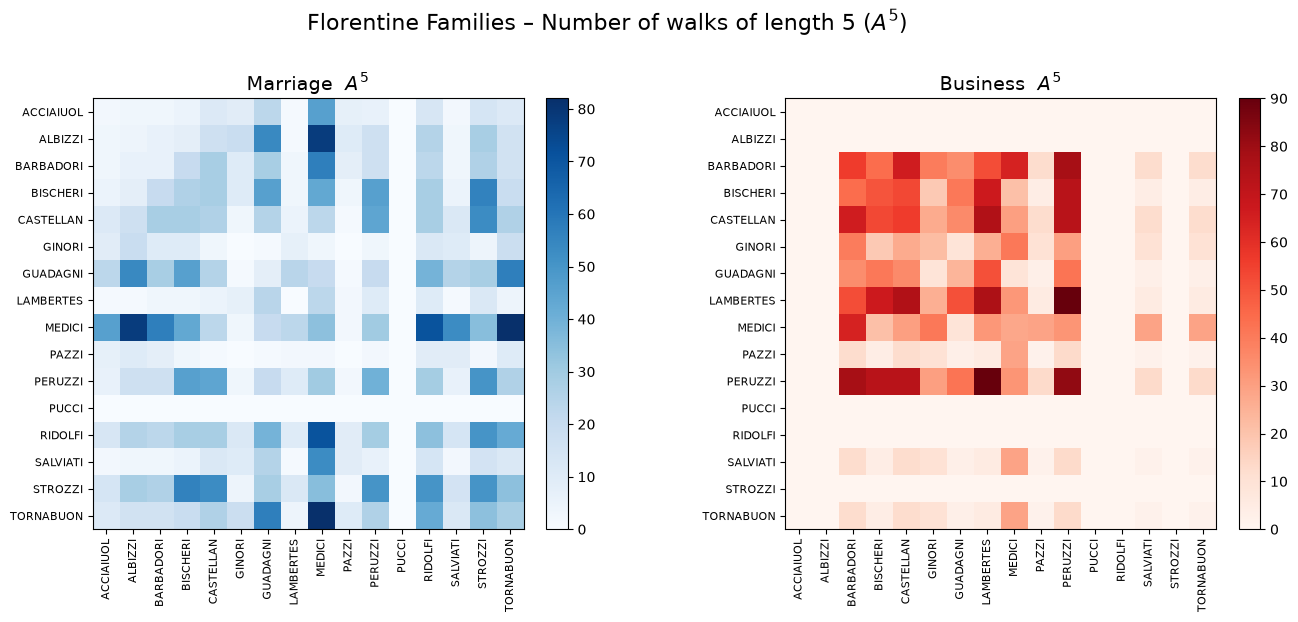

In [50]:
import numpy as np
import matplotlib.pyplot as plt

# A_mar and A_bus are the pandas adjacency matrices from the previous cell
# Convert to numpy for matrix power
# A_mar_np = A_mar.values.astype(float)
# A_bus_np = A_bus.values.astype(float)

# Compute A^N for each layer
N = 5
A_mar_5 = np.linalg.matrix_power(A_mar_np, N)
A_bus_5 = np.linalg.matrix_power(A_bus_np, N)

# -------------------------------------------------
# Side-by-side plots of A^5
# -------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Marriage A^5
im1 = axes[0].imshow(A_mar_5, cmap="Blues")
axes[0].set_title(r"Marriage  $A^{5}$", fontsize=14)
axes[0].set_xticks(range(len(names)))
axes[0].set_yticks(range(len(names)))
axes[0].set_xticklabels(names, rotation=90, fontsize=8)
axes[0].set_yticklabels(names, fontsize=8)
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Business A^5
im2 = axes[1].imshow(A_bus_5, cmap="Reds")
axes[1].set_title(r"Business  $A^{5}$", fontsize=14)
axes[1].set_xticks(range(len(names)))
axes[1].set_yticks(range(len(names)))
axes[1].set_xticklabels(names, rotation=90, fontsize=8)
axes[1].set_yticklabels(names, fontsize=8)
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

fig.suptitle(r"Florentine Families – Number of walks of length 5 ($A^{5}$)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## <font color="green"><b>Exercise 9</b></font>

1. The Medici family has the highest betweenness in the combined network. In the $A^{5}$ matrix we can see that Medici family has a high brokerage beacuse with a legth of 5 is the one with most paths, and in business layer is also important, in this case not the most important, but also important, this makes the Medici family the most influential family in Florece beacuse it connects the other important families int both important social groups (layers in this case).
2. Strozzi has a high degree in Marriage layer and also has a considerable value of betweenness, but for the Business layer it is horrible, this is the highest difference in comaprison to the Medici family.
3. In this case yes, but as said before is not necessary.
4. Connectivity is the number of direct connections a node has. Brokerage is the number of paths that go through your node in order to connect other nodes.
5. Becasue in polithics is really important to be a union point to differenet ideologies and groups, it has the power to speak with both and also to group them or to know both next steps.

# 9. Focus on the Medici family

We now compare **MEDICI** and **STROZZI**. Network measures describe structural opportunities and constraints; they do not by themselves prove historical causality.

In [51]:
focus = centrality_table[centrality_table["family"].isin(["MEDICI", "STROZZI"])].copy()
focus[["family", "degree_marriage", "degree_business", "degree_combined",
       "betweenness_marriage", "betweenness_business", "betweenness_combined"]].round(3)

,family,degree_marriage,degree_business,degree_combined,betweenness_marriage,betweenness_business,betweenness_combined
8,MEDICI,6,5,8,0.452,0.229,0.413
14,STROZZI,4,0,4,0.089,0.000,0.054


## 9.1. Ego networks

An **ego network** contains a focal node, its direct neighbors, and the relationships among those neighbors. It can reveal whether contacts form a closed circle or extend into structurally diverse regions.

In [52]:
medici_ego = nx.ego_graph(G_combined, "MEDICI")
strozzi_ego = nx.ego_graph(G_combined, "STROZZI")

print("MEDICI ego network:", medici_ego.number_of_nodes(), "nodes,", medici_ego.number_of_edges(), "edges")
print("Neighbors:", sorted(G_combined.neighbors("MEDICI")))
print("\nSTROZZI ego network:", strozzi_ego.number_of_nodes(), "nodes,", strozzi_ego.number_of_edges(), "edges")
print("Neighbors:", sorted(G_combined.neighbors("STROZZI")))

MEDICI ego network: 9 nodes, 12 edges
Neighbors: ['ACCIAIUOL', 'ALBIZZI', 'BARBADORI', 'GINORI', 'PAZZI', 'RIDOLFI', 'SALVIATI', 'TORNABUON']

STROZZI ego network: 5 nodes, 6 edges
Neighbors: ['BISCHERI', 'CASTELLAN', 'PERUZZI', 'RIDOLFI']


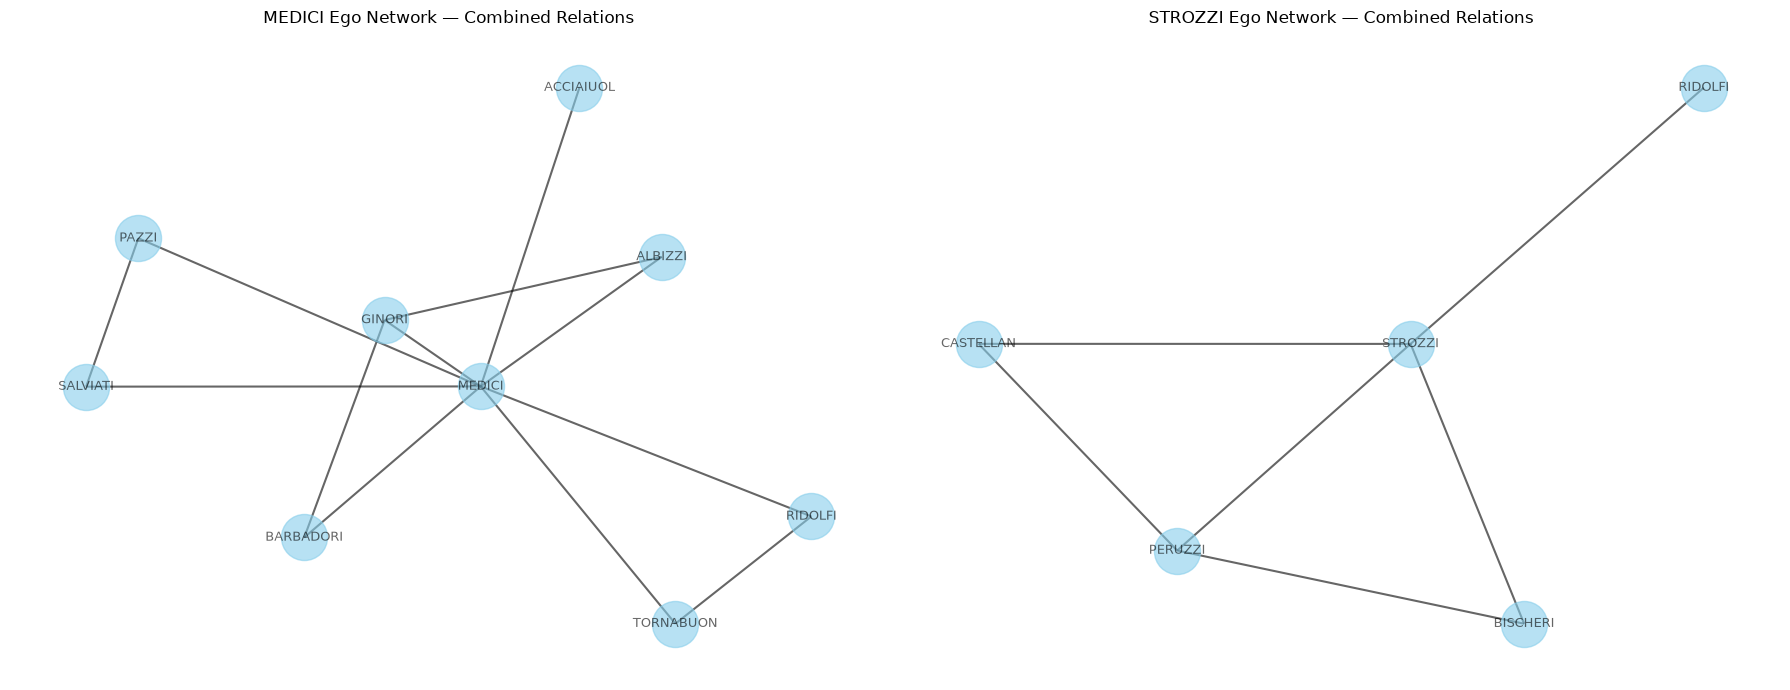

In [53]:
# MEDICI and STROZZI ego networks side by side

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# MEDICI ego network
pos_medici = nx.spring_layout(medici_ego, seed=42)

nx.draw_networkx(medici_ego, pos=pos_medici, ax=axes[0], with_labels=True, node_size=1100, font_size=9, width=1.5, node_color="skyblue", alpha=0.6)

axes[0].set_title("MEDICI Ego Network — Combined Relations")
axes[0].axis("off")


# STROZZI ego network
pos_strozzi = nx.spring_layout(strozzi_ego, seed=42)

nx.draw_networkx(strozzi_ego, pos=pos_strozzi, ax=axes[1], with_labels=True, node_size=1100, font_size=9, width=1.5, node_color="skyblue", alpha=0.6)

axes[1].set_title("STROZZI Ego Network — Combined Relations")
axes[1].axis("off")


plt.tight_layout()
plt.show()

## <font color="red"><b>Exercise 10</b></font>

1. How many direct neighbors does each family have?
2. Are their neighbors highly interconnected?
3. Which ego network appears more closed?
4. Which appears to connect more structurally diverse actors?
5. Relate your observations to betweenness centrality.

## <font color="green"><b>Exercise 10</b></font>

1. The Medici family has 8 direct neighbors, and the Strozzi family has 4.
2. The Medici neighbours are almost all connectes with one neighbour more with exception of one, in the Strozzi family there are 3 neighbour connected and 1 not connected to nor the others.
3. The Strozzi network appears more closed, less nodes also.
4. The Medici network appears more structurally diverse, having 8 neighbours.
5. As we saw in earlier questions, the more diverse netwokr has a hghest betweenness centrality and the one more closed has less.

# 10. Clustering coefficient and closed local circles

The clustering coefficient distinguishes a node whose neighbors all know one another from a node whose neighbors belong to different regions. A family with high degree but relatively low clustering may connect groups that are not strongly linked to one another — a pattern compatible with brokerage.

In [54]:
clustering_combined = nx.clustering(G_combined)
brokerage_table = centrality_table.copy()
brokerage_table["clustering_combined"] = brokerage_table["family"].map(clustering_combined)

brokerage_table[["family", "degree_combined", "betweenness_combined", "clustering_combined"]]     .sort_values("betweenness_combined", ascending=False).reset_index(drop=True).round(3)

,family,degree_combined,betweenness_combined,clustering_combined
0,MEDICI,8,0.413,0.143
1,BARBADORI,4,0.158,0.333
2,GUADAGNI,4,0.112,0.167
3,RIDOLFI,3,0.071,0.333
4,PERUZZI,5,0.061,0.500
5,ALBIZZI,3,0.059,0.333
6,STROZZI,4,0.054,0.333
7,TORNABUON,3,0.052,0.333
8,CASTELLAN,4,0.033,0.500
9,LAMBERTES,4,0.032,0.500


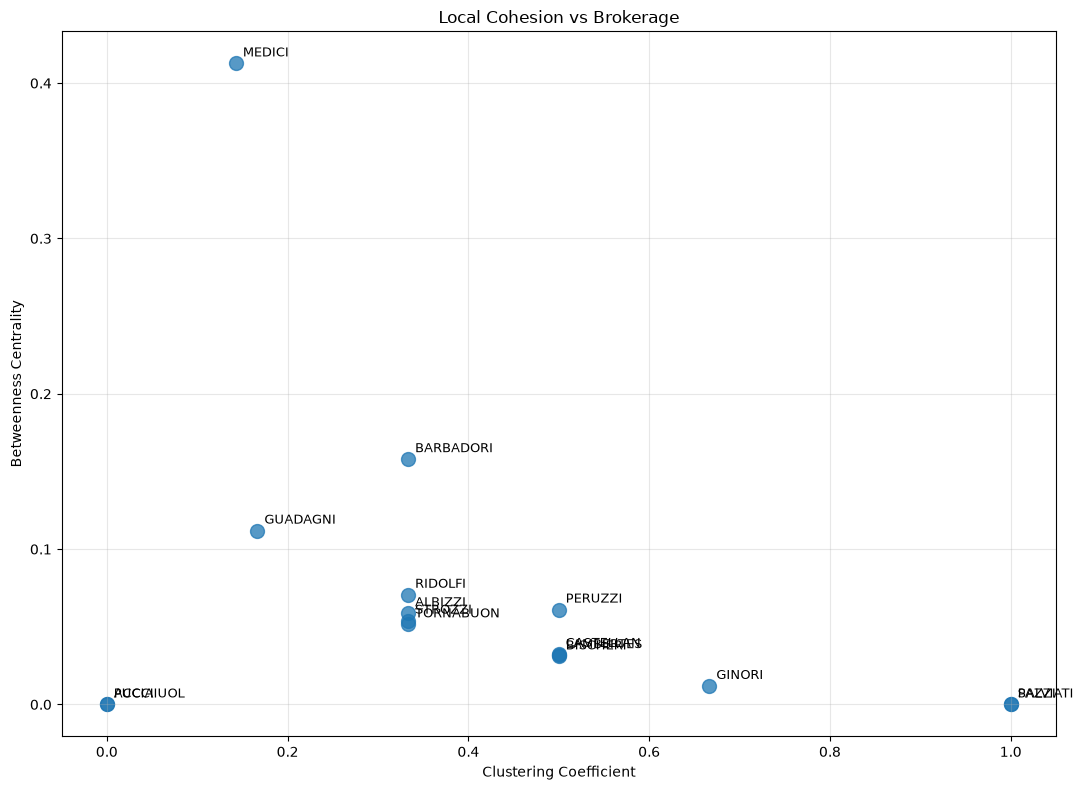

In [55]:
plt.figure(figsize=(11,8))
plt.scatter(brokerage_table["clustering_combined"], brokerage_table["betweenness_combined"], s=100, alpha=0.75)
for _, row in brokerage_table.iterrows():
    plt.annotate(row["family"], (row["clustering_combined"], row["betweenness_combined"]),
                 xytext=(5,5), textcoords="offset points", fontsize=9)
plt.xlabel("Clustering Coefficient"); plt.ylabel("Betweenness Centrality")
plt.title("Local Cohesion vs Brokerage")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## <font color="red"><b>Exercise 11</b></font>

1. Locate MEDICI in the clustering-versus-betweenness plot.
2. Is its neighborhood highly closed or relatively open?
3. Why can low/moderate local clustering coexist with high structural importance?
4. Explain how this combination can be interpreted in terms of brokerage.

## <font color="green"><b>Exercise 11</b></font>

1. The Medici is with a low clustering coefficient and a high betweenness centrality.
2. His neighbours are relatively open.
3. Because the strictural importance depends more in the brokerage than in clustering, is better to connect big diverse groups than closed groups, with diverse groups you can achive more actors.
4. The once with most brokerage have less clustering coefficient, and the once with less brokerage and less connections has more clustering coefficient.

## <font color="red"><b>Exercise 12 — Executive Summary</b></font>

Write an **executive summary of approximately 200–250 words** for a reader who is highly busy, and wants an overview.


## <font color="green"><b>Exercise 12 — Executive Summary</b></font>

## Overview and Key Milestones

This study analyzes political power dynamics in 15th-century Renaissance Florence using **Padgett’s Florentine Families dataset**, a two-layer multiplex network comprising 16 prominent families connected by 20 marriage ties and 15 business ties. Although there are 35 layer-specific ties in total, some ties appear in both layers, resulting in 27 unique family pairs in the combined network.

Using **Pandas**, **NetworkX**, and **Matplotlib**, we evaluated how network topology and structural positioning, rather than wealth alone, help explain the political influence of the **Medici** relative to rival families such as the **Strozzi**.

The main computational milestones of this project include:

1. **Multiplex Structural Mapping:** We analyzed the distinct roles of the marriage and business layers and examined how combining them changes the network's structure. The density increases from approximately 0.167 in the marriage layer and 0.125 in the business layer to 0.225 in the combined network. However, combining the layers can obscure differences in the strategies adopted by individual families. For example, the Strozzi rely exclusively on marriage ties in this dataset (\(k_{\text{mar}} = 4\), \(k_{\text{bus}} = 0\)), whereas the Medici maintain connections through both marriage (\(k_{\text{mar}} = 6\)) and business (\(k_{\text{bus}} = 5\)).

2. **Adjacency Matrix Power Analysis (\(A^n\)):** We examined powers of the adjacency matrices, such as \(A^5\) and \(A^{15}\), to investigate indirect walks through the network. Matrix powers can reveal how families are connected through sequences of relationships, although they count walks rather than necessarily identifying distinct simple paths. This analysis helps explore the structural reach of influential families, including the Medici.

3. **Quantifying Brokerage and Local Cohesion:** We examined betweenness centrality and clustering coefficients in the combined network. The Medici have a reported betweenness centrality of \(C_B = 0.413\), compared with \(0.054\) for the Strozzi, alongside a clustering coefficient of \(C = 0.143\) for the Medici. If confirmed by the computed results, this combination suggests that the Medici occupy a strategic position connecting different parts of the network without being embedded exclusively in tightly interconnected local groups. These measures help explain how structural brokerage may contribute to political influence.

## Future Work and Extensions

To extend and improve this research, future work could focus on the following directions:

- **Weighted and Directed Multiplex Networks:** Incorporate financial transaction values, such as loan sizes and asset values, as well as directed political relationships, such as patronage or voting alliances, where suitable data are available.

- **Temporal Network Dynamics:** Track changes in network structure over time, including the period before and after the Medici exile of 1433–1434, to investigate how centrality and brokerage evolved during periods of political instability.

- **Expanded Node Coverage:** Extend the dataset beyond the 16 elite families to include additional actors, such as guilds, religious institutions, and foreign banking branches, where reliable historical data are available.


## <font color="red"><b>Exercise 13 — Infographic</b></font>

Create a **one-page infographic** entitled:

### *Florentine Families: Networks, Brokerage and the Rise of the Medici*

Should provide a clear view of your findings

## <font color="green"><b>Exercise 13 — Infographic</b></font>

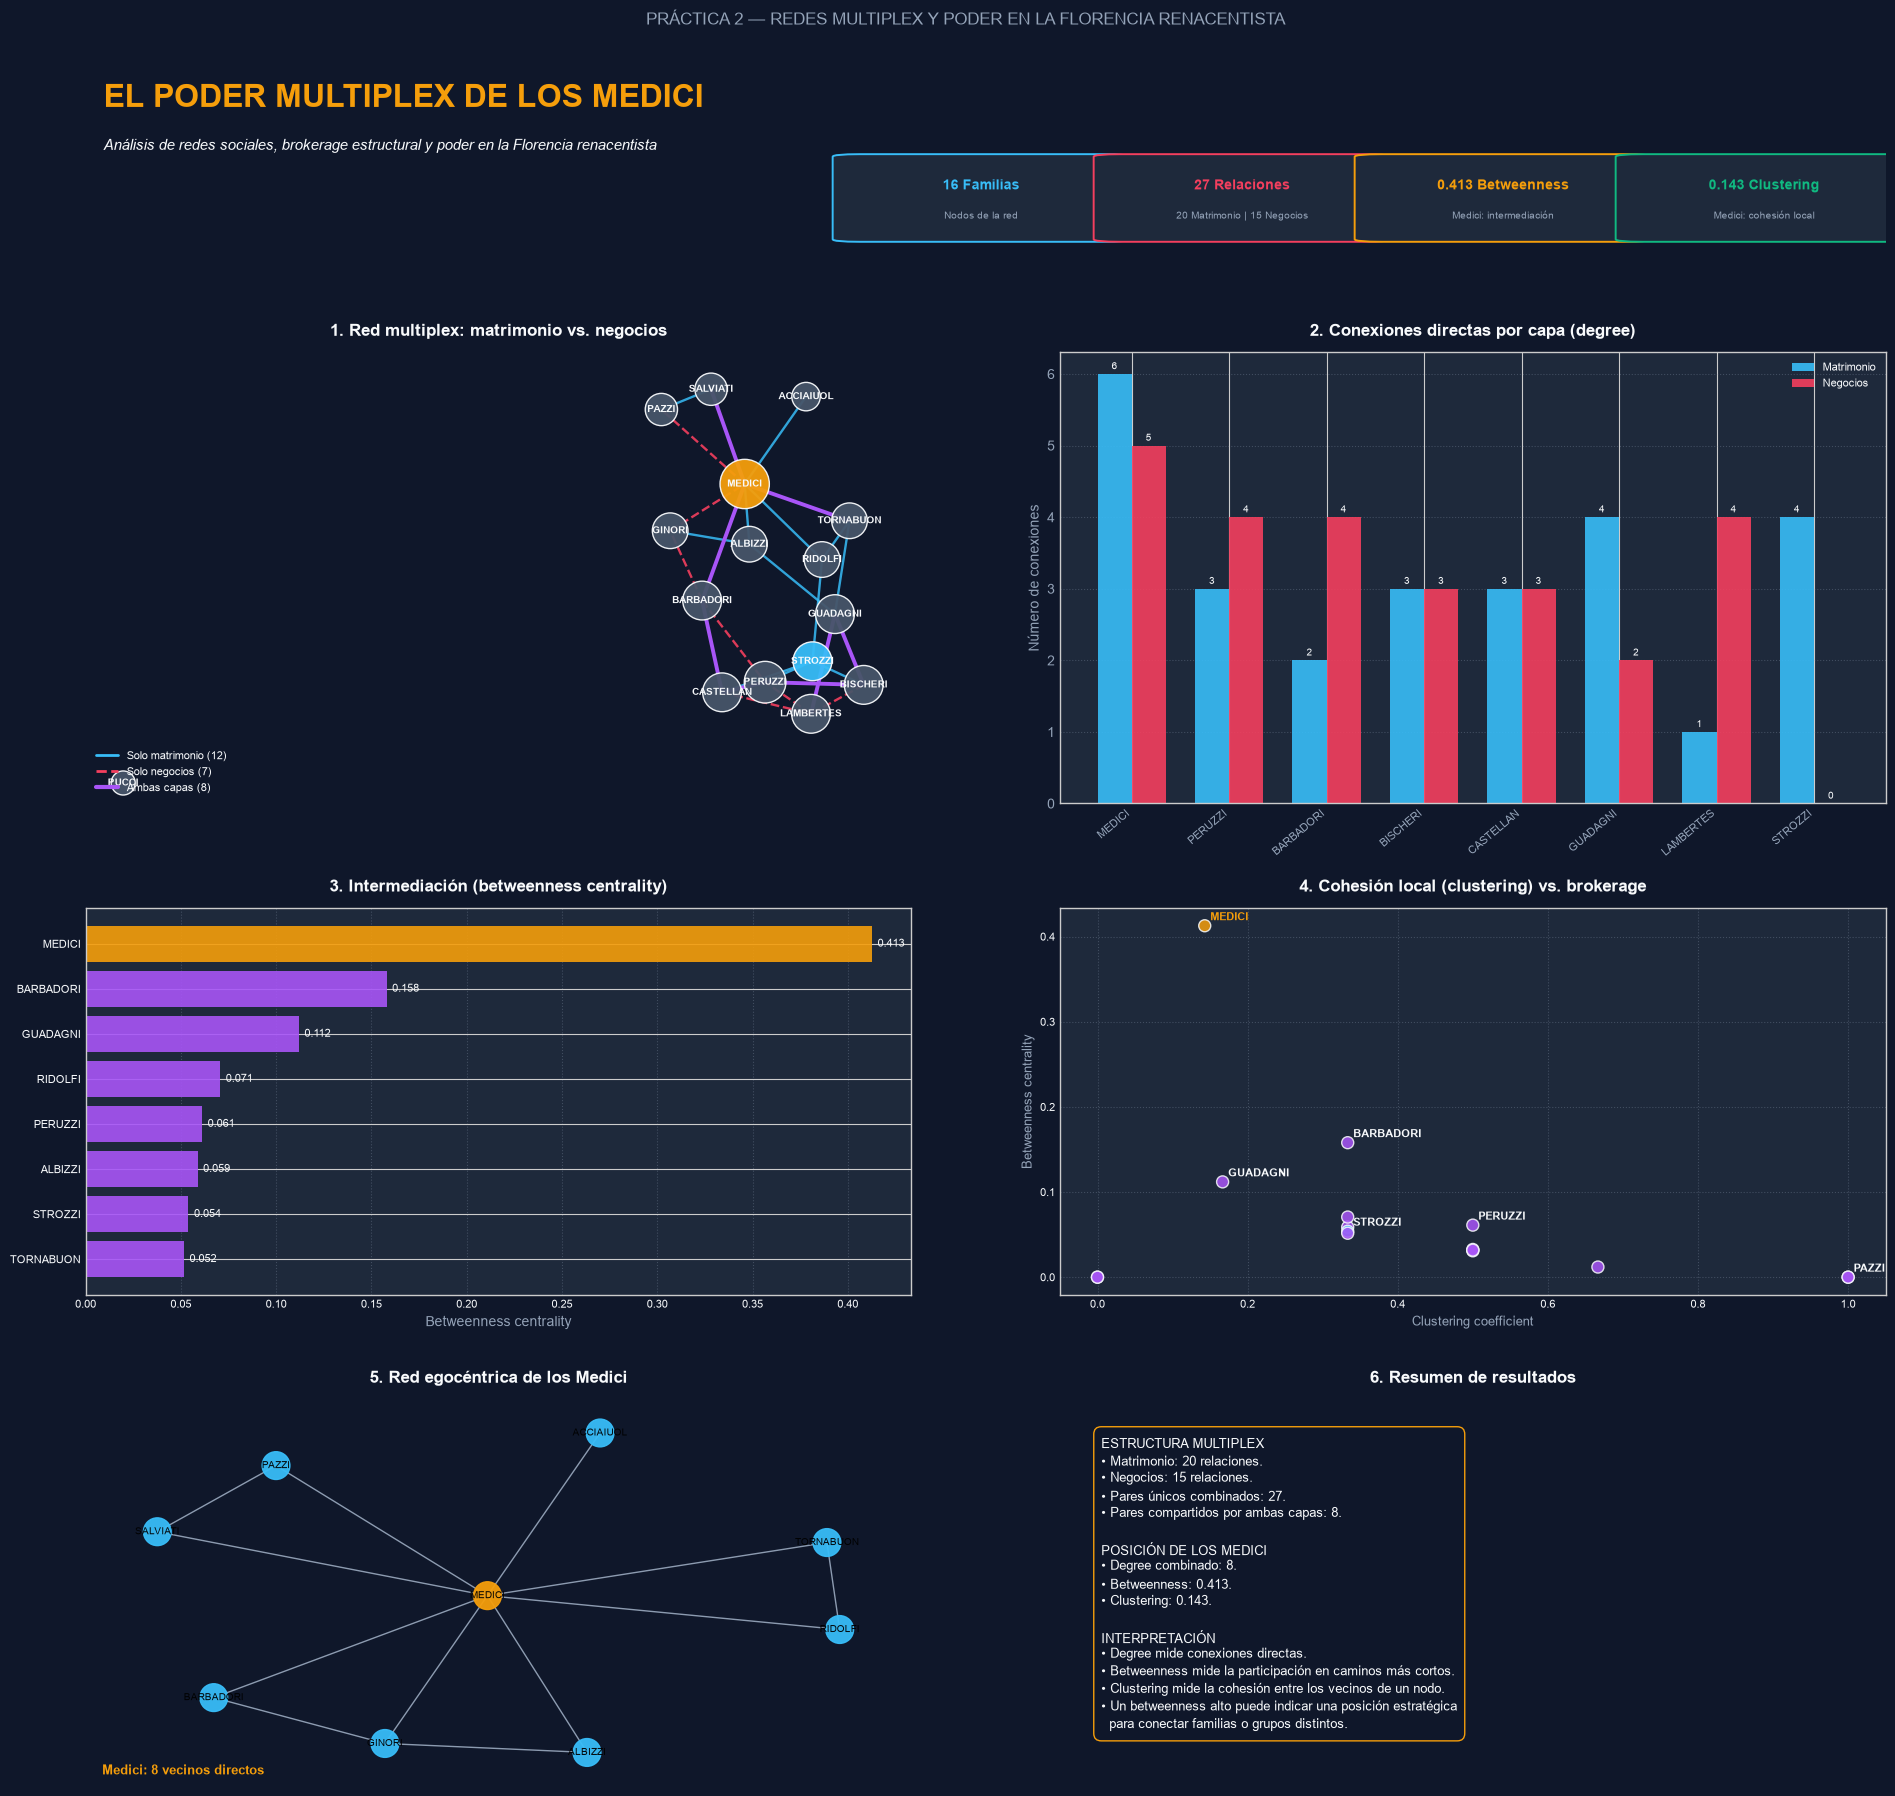

In [56]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import pandas as pd

# ----------------------------------------------------
# CONFIGURACIÓN DE ESTILO Y PALETA DE COLORES
# ----------------------------------------------------

plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

BG_COLOR = "#0F172A"
PANEL_BG = "#1E293B"
TEXT_GOLD = "#F59E0B"
TEXT_LIGHT = "#F8FAFC"
TEXT_MUTED = "#94A3B8"
BLUE_MARRIAGE = "#38BDF8"
RED_BUSINESS = "#F43F5E"
PURPLE_COMBINED = "#A855F7"
GREEN_HIGHLIGHT = "#10B981"

# ----------------------------------------------------
# 1. CONSTRUCCIÓN DE LA RED MULTIPLEX
# ----------------------------------------------------

nodes = [
    "ACCIAIUOL", "ALBIZZI", "BARBADORI", "BISCHERI",
    "CASTELLAN", "GINORI", "GUADAGNI", "LAMBERTES",
    "MEDICI", "PAZZI", "PERUZZI", "PUCCI",
    "RIDOLFI", "SALVIATI", "STROZZI", "TORNABUON"
]

marriage_edges = [
    ("ACCIAIUOL", "MEDICI"),
    ("ALBIZZI", "GINORI"),
    ("ALBIZZI", "GUADAGNI"),
    ("ALBIZZI", "MEDICI"),
    ("BARBADORI", "CASTELLAN"),
    ("BARBADORI", "MEDICI"),
    ("BISCHERI", "GUADAGNI"),
    ("BISCHERI", "PERUZZI"),
    ("BISCHERI", "STROZZI"),
    ("CASTELLAN", "PERUZZI"),
    ("CASTELLAN", "STROZZI"),
    ("GUADAGNI", "LAMBERTES"),
    ("GUADAGNI", "TORNABUON"),
    ("MEDICI", "RIDOLFI"),
    ("MEDICI", "SALVIATI"),
    ("MEDICI", "TORNABUON"),
    ("PAZZI", "SALVIATI"),
    ("PERUZZI", "STROZZI"),
    ("RIDOLFI", "STROZZI"),
    ("RIDOLFI", "TORNABUON")
]

business_edges = [
    ("BARBADORI", "CASTELLAN"),
    ("BARBADORI", "GINORI"),
    ("BARBADORI", "MEDICI"),
    ("BARBADORI", "PERUZZI"),
    ("BISCHERI", "GUADAGNI"),
    ("BISCHERI", "LAMBERTES"),
    ("BISCHERI", "PERUZZI"),
    ("CASTELLAN", "LAMBERTES"),
    ("CASTELLAN", "PERUZZI"),
    ("GINORI", "MEDICI"),
    ("GUADAGNI", "LAMBERTES"),
    ("LAMBERTES", "PERUZZI"),
    ("MEDICI", "PAZZI"),
    ("MEDICI", "SALVIATI"),
    ("MEDICI", "TORNABUON")
]

# Crear los grafos y añadir todas las familias,
# incluidas las que no tienen conexiones en una capa.

G_m = nx.Graph()
G_m.add_nodes_from(nodes)
G_m.add_edges_from(marriage_edges)

G_b = nx.Graph()
G_b.add_nodes_from(nodes)
G_b.add_edges_from(business_edges)

# Red combinada: matrimonio + negocios
G_c = nx.compose(G_m, G_b)

# ----------------------------------------------------
# 2. CÁLCULO DE MÉTRICAS
# ----------------------------------------------------

deg_m = dict(G_m.degree())
deg_b = dict(G_b.degree())
deg_c = dict(G_c.degree())

bet_c = nx.betweenness_centrality(G_c)
clust_c = nx.clustering(G_c)

# Convertir las conexiones en pares no ordenados.
# Así evitamos problemas al comparar (A, B) con (B, A).

marriage_pairs = {frozenset(e) for e in G_m.edges()}
business_pairs = {frozenset(e) for e in G_b.edges()}

marriage_only_pairs = marriage_pairs - business_pairs
business_only_pairs = business_pairs - marriage_pairs
both_pairs = marriage_pairs & business_pairs
combined_pairs = marriage_pairs | business_pairs

# Comprobaciones básicas
assert len(nodes) == 16
assert len(marriage_edges) == 20
assert len(business_edges) == 15

# ----------------------------------------------------
# 3. CREAR EL DISEÑO DEL DASHBOARD
# ----------------------------------------------------

fig = plt.figure(figsize=(20, 19), facecolor=BG_COLOR)

gs = gridspec.GridSpec(
    4, 2,
    height_ratios=[0.8, 2.1, 1.8, 1.8],
    hspace=0.30,
    wspace=0.18,
    left=0.06,
    right=0.96,
    top=0.95,
    bottom=0.05
)

# ----------------------------------------------------
# HEADER Y TARJETAS KPI
# ----------------------------------------------------

ax_head = fig.add_subplot(gs[0, :])
ax_head.set_facecolor(BG_COLOR)
ax_head.axis("off")

ax_head.text(
    0.01, 0.82,
    "EL PODER MULTIPLEX DE LOS MEDICI",
    fontsize=23,
    fontweight="bold",
    color=TEXT_GOLD,
    transform=ax_head.transAxes
)

ax_head.text(
    0.01, 0.57,
    "Análisis de redes sociales, brokerage estructural y poder "
    "en la Florencia renacentista",
    fontsize=11,
    color=TEXT_LIGHT,
    style="italic",
    transform=ax_head.transAxes
)

medici_bet = bet_c["MEDICI"]
medici_clust = clust_c["MEDICI"]

kpis = [
    (f"{len(nodes)} Familias", "Nodos de la red", BLUE_MARRIAGE),
    (
        f"{len(combined_pairs)} Relaciones",
        f"{len(marriage_edges)} Matrimonio | {len(business_edges)} Negocios",
        RED_BUSINESS
    ),
    (f"{medici_bet:.3f} Betweenness", "Medici: intermediación", TEXT_GOLD),
    (f"{medici_clust:.3f} Clustering", "Medici: cohesión local", GREEN_HIGHLIGHT)
]

for idx, (value, label, color) in enumerate(kpis):
    x_pos = 0.43 + idx * 0.145

    rect = patches.FancyBboxPatch(
        (x_pos, 0.05), 0.135, 0.48,
        transform=ax_head.transAxes,
        facecolor=PANEL_BG,
        edgecolor=color,
        linewidth=1.4,
        boxstyle="round,pad=0.015"
    )
    ax_head.add_patch(rect)

    ax_head.text(
        x_pos + 0.0675, 0.34, value,
        transform=ax_head.transAxes,
        fontsize=10,
        fontweight="bold",
        color=color,
        ha="center"
    )

    ax_head.text(
        x_pos + 0.0675, 0.17, label,
        transform=ax_head.transAxes,
        fontsize=7,
        color=TEXT_MUTED,
        ha="center"
    )

# ----------------------------------------------------
# PANEL 1: RED MULTIPLEX COMBINADA
# ----------------------------------------------------

ax_net = fig.add_subplot(gs[1, 0])
ax_net.set_facecolor(PANEL_BG)
ax_net.set_title(
    "1. Red multiplex: matrimonio vs. negocios",
    color=TEXT_LIGHT, fontsize=12, pad=12, fontweight="bold"
)

pos = nx.spring_layout(G_c, seed=42)

node_sizes = [300 + 120 * deg_c[n] for n in nodes]
node_colors = [
    TEXT_GOLD if n == "MEDICI"
    else BLUE_MARRIAGE if n == "STROZZI"
    else "#475569"
    for n in nodes
]

nx.draw_networkx_nodes(
    G_c, pos, ax=ax_net,
    node_size=node_sizes,
    node_color=node_colors,
    alpha=0.95,
    edgecolors=TEXT_LIGHT
)

nx.draw_networkx_labels(
    G_c, pos, ax=ax_net,
    font_size=7,
    font_color=TEXT_LIGHT,
    font_weight="bold"
)

def canonical_edges(pairs):
    """Convertir pares no ordenados a tuplas ordenadas."""
    return [tuple(sorted(pair)) for pair in pairs]

nx.draw_networkx_edges(
    G_c, pos, ax=ax_net,
    edgelist=canonical_edges(marriage_only_pairs),
    width=1.7,
    edge_color=BLUE_MARRIAGE,
    alpha=0.85
)

nx.draw_networkx_edges(
    G_c, pos, ax=ax_net,
    edgelist=canonical_edges(business_only_pairs),
    width=1.7,
    edge_color=RED_BUSINESS,
    style="dashed",
    alpha=0.9
)

nx.draw_networkx_edges(
    G_c, pos, ax=ax_net,
    edgelist=canonical_edges(both_pairs),
    width=2.8,
    edge_color=PURPLE_COMBINED,
    alpha=1.0
)

legend_handles = [
    Line2D([0], [0], color=BLUE_MARRIAGE, lw=2,
           label=f"Solo matrimonio ({len(marriage_only_pairs)})"),
    Line2D([0], [0], color=RED_BUSINESS, lw=2, linestyle="--",
           label=f"Solo negocios ({len(business_only_pairs)})"),
    Line2D([0], [0], color=PURPLE_COMBINED, lw=3,
           label=f"Ambas capas ({len(both_pairs)})")
]

ax_net.legend(
    handles=legend_handles,
    loc="lower left",
    fontsize=8,
    facecolor=BG_COLOR,
    edgecolor="none",
    labelcolor=TEXT_LIGHT
)

ax_net.axis("off")

# ----------------------------------------------------
# PANEL 2: CONEXIONES DIRECTAS POR CAPA
# ----------------------------------------------------

ax_bar = fig.add_subplot(gs[1, 1])
ax_bar.set_facecolor(PANEL_BG)
ax_bar.set_title(
    "2. Conexiones directas por capa (degree)",
    color=TEXT_LIGHT, fontsize=12, pad=12, fontweight="bold"
)

top_fams = sorted(nodes, key=lambda n: deg_c[n], reverse=True)[:8]
x = np.arange(len(top_fams))
width = 0.35

y_m = [deg_m[n] for n in top_fams]
y_b = [deg_b[n] for n in top_fams]

bars_m = ax_bar.bar(
    x - width / 2, y_m, width,
    label="Matrimonio",
    color=BLUE_MARRIAGE, alpha=0.9
)

bars_b = ax_bar.bar(
    x + width / 2, y_b, width,
    label="Negocios",
    color=RED_BUSINESS, alpha=0.9
)

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(
    top_fams, rotation=40, ha="right",
    color=TEXT_LIGHT, fontsize=8
)

ax_bar.tick_params(colors=TEXT_MUTED)
ax_bar.set_ylabel("Número de conexiones", color=TEXT_MUTED)
ax_bar.legend(
    fontsize=8, facecolor=BG_COLOR,
    edgecolor="none", labelcolor=TEXT_LIGHT
)
ax_bar.grid(axis="y", linestyle=":", alpha=0.3, color=TEXT_MUTED)

for bars in [bars_m, bars_b]:
    ax_bar.bar_label(bars, padding=2, fontsize=7, color=TEXT_LIGHT)

# ----------------------------------------------------
# PANEL 3: BETWEENNESS CENTRALITY
# ----------------------------------------------------

ax_bet = fig.add_subplot(gs[2, 0])
ax_bet.set_facecolor(PANEL_BG)
ax_bet.set_title(
    "3. Intermediación (betweenness centrality)",
    color=TEXT_LIGHT, fontsize=12, pad=12, fontweight="bold"
)

sorted_by_bet = sorted(
    nodes, key=lambda n: bet_c[n], reverse=True
)[:8]

values_bet = [bet_c[n] for n in sorted_by_bet]
colors_bet = [
    TEXT_GOLD if n == "MEDICI" else PURPLE_COMBINED
    for n in sorted_by_bet
]

bars = ax_bet.barh(
    sorted_by_bet[::-1],
    values_bet[::-1],
    color=colors_bet[::-1],
    alpha=0.9
)

ax_bet.tick_params(colors=TEXT_LIGHT, labelsize=8)
ax_bet.set_xlabel("Betweenness centrality", color=TEXT_MUTED)
ax_bet.grid(axis="x", linestyle=":", alpha=0.3, color=TEXT_MUTED)

for bar in bars:
    value = bar.get_width()
    ax_bet.annotate(
        f"{value:.3f}",
        (value, bar.get_y() + bar.get_height() / 2),
        xytext=(4, 0),
        textcoords="offset points",
        ha="left", va="center",
        color=TEXT_LIGHT, fontsize=8
    )

# ----------------------------------------------------
# PANEL 4: CLUSTERING VS. BETWEENNESS
# ----------------------------------------------------

ax_scat = fig.add_subplot(gs[2, 1])
ax_scat.set_facecolor(PANEL_BG)
ax_scat.set_title(
    "4. Cohesión local (clustering) vs. brokerage",
    color=TEXT_LIGHT, fontsize=12, pad=12, fontweight="bold"
)

x_clust = [clust_c[n] for n in nodes]
y_bet_all = [bet_c[n] for n in nodes]

point_colors = [
    TEXT_GOLD if n == "MEDICI"
    else BLUE_MARRIAGE if n == "STROZZI"
    else PURPLE_COMBINED
    for n in nodes
]

ax_scat.scatter(
    x_clust, y_bet_all,
    c=point_colors, s=75,
    alpha=0.85, edgecolors=TEXT_LIGHT
)

ax_scat.set_xlabel("Clustering coefficient", color=TEXT_MUTED, fontsize=9)
ax_scat.set_ylabel("Betweenness centrality", color=TEXT_MUTED, fontsize=9)
ax_scat.tick_params(colors=TEXT_LIGHT, labelsize=8)
ax_scat.grid(linestyle=":", alpha=0.3, color=TEXT_MUTED)

for n in ["MEDICI", "STROZZI", "BARBADORI", "GUADAGNI", "PERUZZI", "PAZZI"]:
    label_color = TEXT_GOLD if n == "MEDICI" else TEXT_LIGHT
    ax_scat.annotate(
        n,
        (clust_c[n], bet_c[n]),
        xytext=(4, 4),
        textcoords="offset points",
        color=label_color,
        fontsize=8,
        fontweight="bold"
    )

# ----------------------------------------------------
# PANEL 5: RED EGOCÉNTRICA DE LOS MEDICI
# ----------------------------------------------------

ax_ego = fig.add_subplot(gs[3, 0])
ax_ego.set_facecolor(PANEL_BG)
ax_ego.set_title(
    "5. Red egocéntrica de los Medici",
    color=TEXT_LIGHT, fontsize=12, pad=12, fontweight="bold"
)

medici_ego = nx.ego_graph(G_c, "MEDICI")
pos_m = nx.spring_layout(medici_ego, seed=12)

ego_colors = [
    TEXT_GOLD if n == "MEDICI" else BLUE_MARRIAGE
    for n in medici_ego.nodes()
]

nx.draw_networkx(
    medici_ego, pos_m, ax=ax_ego,
    node_size=400,
    font_size=7,
    node_color=ego_colors,
    font_color="#000000",
    edge_color=TEXT_MUTED,
    alpha=0.95
)

medici_neighbors = list(G_c.neighbors("MEDICI"))

ax_ego.text(
    0.02, 0.03,
    f"Medici: {len(medici_neighbors)} vecinos directos",
    transform=ax_ego.transAxes,
    color=TEXT_GOLD,
    fontsize=9,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor=BG_COLOR,
        alpha=0.9,
        edgecolor="none"
    )
)

ax_ego.axis("off")

# ----------------------------------------------------
# PANEL 6: RESUMEN AUTOMÁTICO
# ----------------------------------------------------

ax_txt = fig.add_subplot(gs[3, 1])
ax_txt.set_facecolor(PANEL_BG)
ax_txt.axis("off")
ax_txt.set_title(
    "6. Resumen de resultados",
    color=TEXT_LIGHT, fontsize=12, pad=12, fontweight="bold"
)

summary_text = (
    "ESTRUCTURA MULTIPLEX\n"
    f"• Matrimonio: {G_m.number_of_edges()} relaciones.\n"
    f"• Negocios: {G_b.number_of_edges()} relaciones.\n"
    f"• Pares únicos combinados: {len(combined_pairs)}.\n"
    f"• Pares compartidos por ambas capas: {len(both_pairs)}.\n\n"
    "POSICIÓN DE LOS MEDICI\n"
    f"• Degree combinado: {deg_c['MEDICI']}.\n"
    f"• Betweenness: {bet_c['MEDICI']:.3f}.\n"
    f"• Clustering: {clust_c['MEDICI']:.3f}.\n\n"
    "INTERPRETACIÓN\n"
    "• Degree mide conexiones directas.\n"
    "• Betweenness mide la participación en caminos más cortos.\n"
    "• Clustering mide la cohesión entre los vecinos de un nodo.\n"
    "• Un betweenness alto puede indicar una posición estratégica\n"
    "  para conectar familias o grupos distintos."
)

ax_txt.text(
    0.05, 0.91,
    summary_text,
    transform=ax_txt.transAxes,
    fontsize=9,
    color=TEXT_LIGHT,
    verticalalignment="top",
    family="sans-serif",
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor=BG_COLOR,
        edgecolor=TEXT_GOLD,
        linewidth=1
    )
)

# ----------------------------------------------------
# FINALIZAR FIGURA
# ----------------------------------------------------

fig.suptitle(
    "PRÁCTICA 2 — REDES MULTIPLEX Y PODER EN LA FLORENCIA RENACENTISTA",
    color=TEXT_MUTED,
    fontsize=12,
    y=0.985
)

plt.show()
